# NeRF ACIT4030: final models

Four models, two scenes, tested on the same held-out views (lego: 20, poster: 29). The baseline is the **same book NeRF MLP for both scenes**.

| Scene | Baseline | Best model |
|---|---|---|
| **Poster** (static, 480 x 270) | Baseline NeRF, 30,000 iterations | **Hash grid + Mip-NeRF 360**, 30,000 iterations |
| **Lego** (bulldozer moves, 200 x 200, trained on train + val = 61 photos) | Baseline NeRF (same model), 10,000 iterations | **D-NeRF** (deformation network + hash grid), 10,000 iterations |

**Sections**
1. Setup (Drive, packages, PyTorch3D wheel, data)
2. Data and shared helpers
3. Poster: baseline NeRF, then the best model (hash grid + Mip-NeRF 360)
4. Lego: baseline NeRF, then D-NeRF, and the side-by-side 360-degree view
5. Training curves
6. Poster results (metrics table, bar charts, ground truth vs rendered)
7. Lego results (metrics table, bar charts, ground truth vs rendered)
8. Summary table and overview of the results folder

**Everything is saved in `ACIT4030/outputs/`, one folder per scene:** all poster results under `outputs/poster/` and all Lego results under `outputs/lego/`. Each has the sub-folders `models`, `checkpoints`, `metrics`, `curves`, `rendered_images`, `training_previews`, `comparisons` and `orbit_360`. Files covering both scenes (summary table, combined curves) are in `outputs/summary/`. The 360-degree comparison of baseline and best model is in `orbit_360` of each scene (`poster_baseline_vs_best_orbit.gif`, `lego_baseline_vs_dnerf_orbit.gif`).

Every training cell resumes from a checkpoint in its scene folder if one exists, and finished models are loaded from their saved weights (set `RETRAIN = True` in section 2 to train everything from scratch).

## 1. Setup

### 1a. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### 1b. Packages and PyTorch3D
Run this cell **before anything else imports torch**. If it installs a different torch and has to restart the runtime, run the Drive cell (1a) and then this cell again.

In [ ]:
import os, sys, glob, subprocess
assert os.path.isdir("/content/drive/MyDrive"), "Drive is not mounted: run cell 1a first"
# Colab's torch changes over time, and a PyTorch3D wheel only works with the torch it was built with.
# Our wheel in Drive was built with torch 2.11 (newer torch such as 2.14 cannot load it and cannot compile PyTorch3D either).
from importlib.metadata import version as _pkg_version
TORCH_PIN = "2.11.0"
if _pkg_version("torch").split("+")[0] != TORCH_PIN:
    print(f"installing torch {TORCH_PIN} (Colab has {_pkg_version('torch')}), about 2-4 min ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", f"torch=={TORCH_PIN}", "torchvision"], check=True)
    if "torch" in sys.modules:                     # torch was already imported in this session: it must restart
        print("torch was already imported, so the runtime restarts now. Run this cell again after it restarts.")
        os.kill(os.getpid(), 9)
import torch

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "fvcore", "iopath", "lpips", "torchmetrics"], check=True)
# PyTorch3D: (1) already installed? (2) wheel built earlier in Drive, (3) otherwise build a CPU-only wheel and save it
WHEEL_DIR = "/content/drive/MyDrive/colab_Packages/pytorch3d_build/wheels"     # where your earlier wheel lives
TORCH_DIR = f"{WHEEL_DIR}/torch{torch.__version__.split('+')[0]}"              # wheels built for THIS torch version
PY_TAG = f"cp{sys.version_info.major}{sys.version_info.minor}"

def p3d_works():
    try:
        import importlib; importlib.invalidate_caches()
        import pytorch3d, pytorch3d.renderer            # the renderer imports the compiled part (_C)
        return True
    except Exception as e:                               # missing, or built for another torch version
        print("  PyTorch3D not usable:", type(e).__name__, str(e)[:150])
        return False

def wheels_in(d):
    return [w for w in sorted(glob.glob(d + "/pytorch3d*.whl")) if PY_TAG in os.path.basename(w)]

if not p3d_works():
    os.makedirs(TORCH_DIR, exist_ok=True)
    for d in (TORCH_DIR, WHEEL_DIR):                     # exact torch match first, then any wheel for this Python
        for w in wheels_in(d)[-1:]:
            print("trying wheel:", w)
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall", w])
            if p3d_works(): break
        if p3d_works(): break
    if not p3d_works():
        print("Building PyTorch3D for torch", torch.__version__, "(CPU-only), usually 5-10 min, no output until it finishes ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "setuptools", "wheel", "ninja", "fvcore", "iopath"])
        env = {**os.environ, "FORCE_CUDA": "0", "CUDA_VISIBLE_DEVICES": ""}
        p = subprocess.run([sys.executable, "-m", "pip", "wheel", "-v", "--no-deps", "--no-build-isolation", "-w", TORCH_DIR,
                            "git+https://github.com/facebookresearch/pytorch3d.git@stable"],
                           env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        open("/content/p3d_build_cpu.log", "w").write(p.stdout)
        print("build exit code:", p.returncode); print("\n".join(p.stdout.splitlines()[-15:]))
        assert wheels_in(TORCH_DIR), "PyTorch3D wheel was not built: send the lines above (full log: /content/p3d_build_cpu.log)"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall", wheels_in(TORCH_DIR)[-1]])
    assert p3d_works(), "PyTorch3D still not importable"
import pytorch3d
print("PyTorch3D", pytorch3d.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

installing torch 2.11.0 (Colab has 2.14.1+cu130), about 2-4 min ...
  PyTorch3D not usable: ModuleNotFoundError No module named 'pytorch3d'
  PyTorch3D not usable: ModuleNotFoundError No module named 'pytorch3d'
trying wheel: /content/drive/MyDrive/colab_Packages/pytorch3d_build/wheels/pytorch3d-0.7.8-cp313-cp313-linux_x86_64.whl
PyTorch3D 0.7.8 | torch 2.11.0+cu130 | GPU: NVIDIA A100-SXM4-40GB


### 1c. Course data

In [ ]:
# Course data -> /content/acit4030-ass2/data (lego, poster, load_nerf_data.py). Looks in both Drive folders.
import os, glob, shutil, zipfile

D = "/content/acit4030-ass2/data"
ROOTS = ["/content/drive/MyDrive/acit4030-ass2", "/content/drive/MyDrive/ACIT4030"]
ok = lambda p: "__MACOSX" not in p

def find_scene_dirs(root):
    dirs = sorted({os.path.dirname(p) for p in glob.glob(root + "/**/transforms*.json", recursive=True) if ok(p)})
    lego = next((d for d in dirs if "lego" in d.lower()), None)
    poster = next((d for d in dirs if "poster" in d.lower()), None)
    loader = next((p for p in glob.glob(root + "/**/load_nerf_data*.py", recursive=True) if ok(p)), None)
    return lego, poster, loader

if not all(os.path.exists(f"{D}/{x}") for x in ("lego", "poster", "load_nerf_data.py")):
    found = None
    for root in ROOTS:
        r = find_scene_dirs(root)
        print(root, "->", r)
        if all(r): found = r; break
    if not found:                                          # maybe the data is still inside a zip
        for root in ROOTS:
            for z in glob.glob(root + "/**/*.zip", recursive=True):
                with zipfile.ZipFile(z) as zf:
                    if any(n.endswith("load_nerf_data.py") and ok(n) for n in zf.namelist()):
                        print("unzipping", z); zf.extractall("/content/_data"); break
        found = find_scene_dirs("/content/_data")
    assert all(found), "lego, poster and load_nerf_data.py not found in My Drive/acit4030-ass2 or My Drive/ACIT4030"
    lego, poster, loader = found
    os.makedirs(D, exist_ok=True)
    shutil.copytree(lego, f"{D}/lego", dirs_exist_ok=True)
    shutil.copytree(poster, f"{D}/poster", dirs_exist_ok=True)
    shutil.copy(loader, f"{D}/load_nerf_data.py")
print(sorted(os.listdir(D)))        # should show: ['lego', 'load_nerf_data.py', 'poster']

/content/drive/MyDrive/acit4030-ass2 -> ('/content/drive/MyDrive/acit4030-ass2/data/lego', '/content/drive/MyDrive/acit4030-ass2/data/poster', '/content/drive/MyDrive/acit4030-ass2/data/load_nerf_data.py')
['lego', 'load_nerf_data.py', 'poster']


## 2. Imports, helpers and data

In [ ]:
import os, sys, json, math, time, gc
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

DATA_ROOT = "/content/acit4030-ass2"


sys.path.append(DATA_ROOT + "/data")
from load_nerf_data import load_nerf_data
from pytorch3d.renderer import (FoVPerspectiveCameras, NDCMultinomialRaysampler, MonteCarloRaysampler,
                                EmissionAbsorptionRaymarcher, ImplicitRenderer)
from pytorch3d.io import IO

device = torch.device("cuda:0")
OUT = "/content/drive/MyDrive/ACIT4030/outputs"
os.makedirs(OUT, exist_ok=True)

# Everything the notebook saves goes into ONE folder per scene (outputs/poster and outputs/lego), sorted by kind:
#   models/             trained weights (.pt)
#   checkpoints/        resume files (.pt)
#   metrics/            *_metrics.json, *_per_view.csv, results tables (.csv)
#   curves/             training / test PSNR curves (.png + .csv) and training histories (.json)
#   rendered_images/    <model>/ test_views.png, test_renders.npz, rendered/ and ground_truth/ (one PNG per test view)
#   training_previews/  <model>/ preview pictures made during training
#   comparisons/        ground truth vs rendered figures and metric bar charts
#   orbit_360/          360-degree GIFs (and frames), incl. the side-by-side baseline vs best model
# outputs/summary holds the files that cover both scenes (results_all_models.csv, training_curves.png).
RES = OUT
SCENES = ("poster", "lego")
KINDS = ("models", "checkpoints", "metrics", "curves", "rendered_images", "training_previews", "comparisons", "orbit_360")
def make_result_dirs():
    for sc in SCENES:
        for k in KINDS: os.makedirs(f"{OUT}/{sc}/{k}", exist_ok=True)
    os.makedirs(f"{OUT}/summary", exist_ok=True)
def rf(kind, filename):
    """Path of a result file: outputs/<scene>/<kind>/<filename>. The scene is read from the file name
    ('poster' or 'lego'); files that belong to neither go to outputs/summary."""
    sc = "poster" if "poster" in filename else ("lego" if "lego" in filename else None)
    path = f"{OUT}/{sc}/{kind}/{filename}" if sc else f"{OUT}/summary/{filename}"
    os.makedirs(os.path.dirname(path), exist_ok=True)
    return path
def rdir(kind, name):
    """Folder outputs/<scene>/<kind>/<name>/ (one sub-folder per model), created if needed."""
    return os.path.dirname(rf(kind, f"{name}/_"))
make_result_dirs()


def huber(x, y, scaling=0.1):
    diff_sq = (x - y) ** 2
    return ((1 + diff_sq / (scaling ** 2)).clamp(1e-4).sqrt() - 1) * float(scaling)


def positional_encoding(x, n_freqs):
    """[x] -> [sin(2^k x), cos(2^k x)] for k = 0 .. n_freqs-1."""
    freqs = 2.0 ** torch.arange(n_freqs, device=x.device)
    xf = (x[..., None] * freqs).flatten(-2)
    return torch.cat([xf.sin(), xf.cos()], dim=-1)


def build_renderers(H, W, near, far, n_pts=128, n_rays=750):
    """Monte Carlo renderer (training) and full-grid renderer (whole images). Works for non-square images."""
    sx, sy = max(W / H, 1.0), max(H / W, 1.0)          # PyTorch3D NDC: shorter side spans [-1, 1]
    rm = EmissionAbsorptionRaymarcher()
    mc = MonteCarloRaysampler(min_x=-sx, max_x=sx, min_y=-sy, max_y=sy,
                              n_rays_per_image=n_rays, n_pts_per_ray=n_pts,
                              min_depth=near, max_depth=far)
    grid = NDCMultinomialRaysampler(image_height=H, image_width=W, n_pts_per_ray=n_pts,
                                    min_depth=near, max_depth=far)
    return (ImplicitRenderer(raysampler=mc, raymarcher=rm).to(device),
            ImplicitRenderer(raysampler=grid, raymarcher=rm).to(device))


def sample_images_at_mc_locs(target_images, sampled_rays_xy):
    """Ground-truth colours at the Monte Carlo ray positions (NDC coords rescaled for non-square images)."""
    ba, H, W, dim = target_images.shape
    scale = torch.tensor([max(W / H, 1.0), max(H / W, 1.0)], device=sampled_rays_xy.device)
    spatial_size = sampled_rays_xy.shape[1:-1]
    sampled = F.grid_sample(target_images.permute(0, 3, 1, 2),
                            -(sampled_rays_xy / scale).view(ba, -1, 1, 2), align_corners=True)
    return sampled.permute(0, 2, 3, 1).view(ba, *spatial_size, dim)


import lpips
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
lpips_fn = lpips.LPIPS(net="alex", verbose=False).to(device)

@torch.no_grad()
def compute_metrics(pred, gt):
    """pred, gt: (N, H, W, 3) in [0, 1]. Returns per-image PSNR, SSIM, LPIPS."""
    p, g = pred.permute(0, 3, 1, 2), gt.permute(0, 3, 1, 2)
    psnr = -10 * torch.log10(((p - g) ** 2).flatten(1).mean(1))
    ssim = ssim_fn(p, g, data_range=1.0, reduction="none")
    lp = lpips_fn(p * 2 - 1, g * 2 - 1).flatten()
    return {"psnr": psnr.cpu(), "ssim": ssim.cpu(), "lpips": lp.cpu()}

# the baseline uses the book's NeRF MLP (same code as the earlier notebooks)
BOOK_DIR = "/content/book"
if not os.path.exists(BOOK_DIR):
    subprocess.check_call(["git", "clone", "-q", "https://github.com/PacktPublishing/3D-Deep-Learning-with-Python.git", BOOK_DIR])
sys.path.append(BOOK_DIR + "/chap6")
from nerf_model import NeuralRadianceField

print("helpers ready")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 199MB/s]


helpers ready


In [ ]:
# RETRAIN switch.  True  = train every model from scratch in this session.
#                  False = reuse finished checkpoints / weights from Drive (also use False to resume after a disconnect).
RETRAIN = True

import glob, shutil, datetime
if RETRAIN:
    old = f"{OUT}/previous_runs/run_{datetime.datetime.now().strftime('%Y%m%d_%H%M')}"
    os.makedirs(old, exist_ok=True)
    moved = []
    for d in ("poster", "lego", "summary", "results"):               # the previous results folders
        if os.path.isdir(f"{OUT}/{d}"):
            shutil.move(f"{OUT}/{d}", f"{old}/{d}"); moved.append(d)
    names = ["poster_baseline_nerf_30k", "poster_ours_hash_m360_480_30k", "lego_baseline_nerf_200_10k",
             "lego_baseline_static_200_10k", "lego_baseline_time_200_10k",
             "lego_dnerf_trainval_200_10k", "lego_dnerf_200_tv_10k"]
    n_loose = 0
    for n in names:                                                 # loose files from older versions of the notebook
        for f in glob.glob(f"{OUT}/{n}*"):
            if os.path.isfile(f):
                shutil.move(f, os.path.join(old, os.path.basename(f))); n_loose += 1
    print(f"RETRAIN = True: moved {moved} and {n_loose} loose files to {old} (nothing deleted). All models will train from scratch.")
else:
    print("RETRAIN = False: finished checkpoints / weights in the results folders will be loaded.")
make_result_dirs()
print("results folders:", f"{OUT}/poster", f"{OUT}/lego")
print("GPU:", torch.cuda.get_device_name(0))


RETRAIN = True: moved ['poster', 'lego', 'summary'] and 50 loose files to /content/drive/MyDrive/ACIT4030/outputs/previous_runs/run_20261116_1521 (nothing deleted). All models will train from scratch.
results folders: /content/drive/MyDrive/ACIT4030/outputs/poster /content/drive/MyDrive/ACIT4030/outputs/lego
GPU: NVIDIA A100-SXM4-40GB


### Lego: train / val / test with corrected cameras

In [ ]:
LEGO = DATA_ROOT + "/data/lego"
NEAR, FAR = 2.0, 6.0
LEGO_HW = 100

def fixed_cameras(cams, transforms_path, device):
    """Camera poses straight from the json file (OpenGL axes -> PyTorch3D axes)."""
    meta = json.load(open(transforms_path))
    c2w = torch.tensor([f["transform_matrix"] for f in meta["frames"]], dtype=torch.float32)
    flip = torch.diag(torch.tensor([-1., 1., -1.]))
    R = c2w[:, :3, :3] @ flip
    C = c2w[:, :3, 3]
    T = -torch.einsum("nji,nj->ni", R, C)
    return FoVPerspectiveCameras(R=R, T=T, fov=cams.fov, degrees=True,
                                 znear=cams.znear, zfar=cams.zfar, device=device)

def load_lego(split):
    im, sil, c = load_nerf_data(LEGO, split=split, device=device, znear=NEAR, zfar=FAR,
                                resize_to=(LEGO_HW, LEGO_HW))
    return im.clamp(0, 1), sil.clamp(0, 1), fixed_cameras(c, LEGO + f"/transforms_{split}.json", device)

l_train_imgs, l_train_sils, l_train_cams = load_lego("train")
l_val_imgs, _, l_val_cams = load_lego("val")
l_test_imgs, _, l_test_cams = load_lego("test")
l_renderer_mc, l_renderer_grid = build_renderers(LEGO_HW, LEGO_HW, NEAR, FAR)
print("lego train:", tuple(l_train_imgs.shape), "| test:", tuple(l_test_imgs.shape))

Loading transforms_train.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading train split with 50 frames.
Loaded image dimensions: 800x800
Resizing images to: 100x100
Calculated Vertical FOV for camera: 39.598 degrees
Loading transforms_val.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading val split with 11 frames.
Loaded image dimensions: 800x800
Resizing images to: 100x100
Calculated Vertical FOV for camera: 39.598 degrees
Loading transforms_test.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading test split with 20 frames.
Loaded image dimensions: 800x800
Resizing images to: 100x100
Calculated Vertical FOV for camera: 39.598 degrees
lego train: (50, 100, 100, 3) | test: (20, 100, 100, 3)


### Lego: time of every frame (the bulldozer moves, so each photo has a time value)

In [ ]:
# D-NeRF step 1: the time of every lego frame (same order as the images and cameras)

def load_times(split, n_expected):
    meta = json.load(open(f"{LEGO}/transforms_{split}.json"))
    t = torch.tensor([f["time"] for f in meta["frames"]], dtype=torch.float32, device=device)
    assert len(t) == n_expected, f"{split}: {len(t)} times but {n_expected} images"
    return t

l_train_times = load_times("train", len(l_train_imgs))
l_val_times = load_times("val", len(l_val_imgs))
l_test_times = load_times("test", len(l_test_imgs))
print("train times:", l_train_times.min().item(), "to", l_train_times.max().item(),
      "| test times:", l_test_times.min().item(), "to", l_test_times.max().item())

train times: 0.0 to 1.0 | test times: 0.0 to 1.0


### Lego at 200 x 200, train + val (the setup used for the best D-NeRF and for both lego baselines)

In [ ]:
# Lego at 200 x 200 on train + val (61 photos): the setup of the best D-NeRF. The lego baselines use exactly the same data.
from pytorch3d.renderer.camera_utils import join_cameras_as_batch

HW2 = 200
def load_lego_hw(split, hw):
    im, sil, c = load_nerf_data(LEGO, split=split, device=device, znear=NEAR, zfar=FAR, resize_to=(hw, hw))
    return im.clamp(0, 1), sil.clamp(0, 1), fixed_cameras(c, LEGO + f"/transforms_{split}.json", device)

tr2, va2, te2 = load_lego_hw("train", HW2), load_lego_hw("val", HW2), load_lego_hw("test", HW2)
imgs2, sils2 = torch.cat([tr2[0], va2[0]]), torch.cat([tr2[1], va2[1]])      # 61 training photos, 200 x 200
cams2 = join_cameras_as_batch([tr2[2], va2[2]])
tv_times = torch.cat([l_train_times, l_val_times])                          # time of every training photo
r_mc2, r_grid2 = build_renderers(HW2, HW2, NEAR, FAR)
print("lego training photos (train + val):", tuple(imgs2.shape), "| test photos:", tuple(te2[0].shape))

Loading transforms_train.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading train split with 50 frames.
Loaded image dimensions: 800x800
Resizing images to: 200x200
Calculated Vertical FOV for camera: 39.598 degrees
Loading transforms_val.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading val split with 11 frames.
Loaded image dimensions: 800x800
Resizing images to: 200x200
Calculated Vertical FOV for camera: 39.598 degrees
Loading transforms_test.json
Using camera_angle_x: 0.691 rad, calculated FOV: 39.598 deg
Loading test split with 20 frames.
Loaded image dimensions: 800x800
Resizing images to: 200x200
Calculated Vertical FOV for camera: 39.598 degrees
lego training photos (train + val): (61, 200, 200, 3) | test photos: (20, 200, 200, 3)


### Poster: images, corrected cameras, split (every 8th frame is a test view)

In [ ]:
POSTER = DATA_ROOT + "/data/poster"
POSTER_H, POSTER_W = 480, 270     # earlier runs used 240 x 135; set 480, 270 for 2x sharper training images
NEAR_P, FAR_P = 0.3, 11.0

meta_p = json.load(open(POSTER + "/transforms.json"))
P = IO().load_pointcloud(POSTER + "/sparse_pc.ply").points_packed()

p_imgs_all, p_sils_all, _ = load_nerf_data(POSTER, split="train", device="cpu", znear=NEAR_P, zfar=FAR_P,
                                           resize_to=(POSTER_H, POSTER_W))
p_imgs_all = p_imgs_all.clamp(0, 1).to(device)
p_sils_all = p_sils_all.clamp(0, 1).to(device)

fov_p = math.degrees(2 * math.atan(0.5 * meta_p["w"] / meta_p["fl_x"]))   # FoV of the shorter side (width)

def make_cameras(meta, idx, fov_deg, znear, zfar, device):
    """NeRF/OpenGL camera-to-world -> PyTorch3D world-to-camera."""
    c2w = torch.tensor([meta["frames"][i]["transform_matrix"] for i in idx], dtype=torch.float32)
    flip = torch.diag(torch.tensor([-1., 1., -1.]))
    R = c2w[:, :3, :3] @ flip
    C = c2w[:, :3, 3]
    T = -torch.einsum("nji,nj->ni", R, C)
    return FoVPerspectiveCameras(R=R, T=T, fov=fov_deg, degrees=True, znear=znear, zfar=zfar, device=device)

all_idx = list(range(len(meta_p["frames"])))
p_test_idx = all_idx[::8]
p_train_idx = [i for i in all_idx if i % 8 != 0]
p_train_cams = make_cameras(meta_p, p_train_idx, fov_p, NEAR_P, FAR_P, device)
p_test_cams = make_cameras(meta_p, p_test_idx, fov_p, NEAR_P, FAR_P, device)
p_train_imgs, p_train_sils = p_imgs_all[p_train_idx], p_sils_all[p_train_idx]
p_test_imgs = p_imgs_all[p_test_idx]
p_train_idx_t = torch.tensor(p_train_idx, device=device)   # original frame index of each training image
p_renderer_mc, p_renderer_grid = build_renderers(POSTER_H, POSTER_W, NEAR_P, FAR_P)
print(f"poster FoV {fov_p:.2f} deg | train: {tuple(p_train_imgs.shape)} | test: {tuple(p_test_imgs.shape)}")

Using explicit intrinsics from transforms.json (scaled for 270x480):
  fl_x=286.79, fl_y=289.71, cx=135.00, cy=240.00
Loading train split with 226 frames.
Loaded image dimensions: 1080x1920
Resizing images to: 270x480
Calculated Vertical FOV for camera: 79.278 degrees
Found 'applied_transform' in transforms.json. Applying it to camera poses.
poster FoV 50.42 deg | train: (197, 480, 270, 3) | test: (29, 480, 270, 3)


### Scene helpers (centre/scale, contraction, compositing weights)

In [ ]:
def scene_center_scale(cams):
    """Centre = point closest (least squares) to all camera viewing rays; scale = mean camera distance to it."""
    C = cams.get_camera_center().detach().cpu().double()
    fwd = F.normalize(cams.R[:, :, 2].detach().cpu().double(), dim=-1)     # PyTorch3D: camera looks along +z
    proj = torch.eye(3, dtype=torch.float64)[None] - fwd[:, :, None] * fwd[:, None, :]
    center = torch.linalg.solve(proj.sum(0), (proj @ C[:, :, None]).sum(0).squeeze(-1))
    return center.float(), float((C - center).norm(dim=-1).mean())


def contract(x):
    """Mip-NeRF 360 contraction: unchanged inside the unit ball, squeezed into the shell between radius 1 and 2."""
    n = x.norm(dim=-1, keepdim=True).clamp(min=1e-6)
    return torch.where(n <= 1.0, x, (2.0 - 1.0 / n) * (x / n))


def weights_from_alpha(alpha):
    """Compositing weights w_i = alpha_i * prod_{j<i} (1 - alpha_j)."""
    ones = torch.ones_like(alpha[..., :1])
    trans = torch.cumprod(torch.cat([ones, 1.0 - alpha + 1e-10], dim=-1), dim=-1)[..., :-1]
    return alpha * trans


lego_center, lego_scale = torch.zeros(3), 1.5           # the lego object sits at the origin and fills the unit ball
print("lego centre", lego_center.numpy(), "scale", lego_scale)

lego centre [0. 0. 0.] scale 1.5


### Evaluation and 360-degree view
Both take a `render_fn(cameras) -> (1, H, W, 3)`, so they work for any model.

In [ ]:
@torch.no_grad()
def evaluate(render_fn, cams, imgs, name, scene, stats=None, show=(0, 7, 14, 21), times=None):
    """Render every test view, print the metrics, save everything (metrics, renders, figure), show a few views."""
    import csv
    from PIL import Image as _PIL
    renders = torch.cat([render_fn(cams[[i]]) if times is None else render_fn(cams[[i]], times[[i]])
                         for i in range(len(cams))])   # times given: every view at its own time
    m = compute_metrics(renders, imgs)

    img_dir = rdir("rendered_images", name)                                    # results/rendered_images/<name>/
    r8 = (renders.clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)
    g8 = (imgs.clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)
    np.savez_compressed(f"{img_dir}/test_renders.npz", renders=r8)
    os.makedirs(f"{img_dir}/rendered", exist_ok=True); os.makedirs(f"{img_dir}/ground_truth", exist_ok=True)
    for i in range(len(r8)):                                                   # one PNG per test view
        _PIL.fromarray(r8[i]).save(f"{img_dir}/rendered/view_{i:02d}.png")
        _PIL.fromarray(g8[i]).save(f"{img_dir}/ground_truth/view_{i:02d}.png")

    print(f"{'':45s}{'PSNR':>8s}{'SSIM':>8s}{'LPIPS':>8s}")
    print(f"{name:45s}{m['psnr'].mean():8.2f}{m['ssim'].mean():8.3f}{m['lpips'].mean():8.3f}")
    if stats:
        print(f"train time: {stats['train_min']:.1f} min | peak memory: {stats['peak_mem_gb']:.2f} GB")
    json.dump({**{k: v.tolist() for k, v in m.items()}, **(stats or {})},
              open(rf("metrics", f"{name}_metrics.json"), "w"), indent=2)
    with open(rf("metrics", f"{name}_per_view.csv"), "w", newline="") as fh:   # metrics of every test view
        w = csv.writer(fh); w.writerow(["view", "psnr", "ssim", "lpips"])
        for i in range(len(r8)): w.writerow([i, float(m["psnr"][i]), float(m["ssim"][i]), float(m["lpips"][i])])

    show = [i for i in show if i < len(cams)]
    fig, ax = plt.subplots(3, len(show), figsize=(2.6 * len(show) if scene == "poster" else 3 * len(show), 11))
    for j, i in enumerate(show):
        ax[0, j].imshow(imgs[i].cpu()); ax[0, j].set_title(f"Ground truth #{i}")
        ax[1, j].imshow(renders[i].cpu()); ax[1, j].set_title(f"{m['psnr'][i]:.1f} dB")
        ax[2, j].imshow((renders[i] - imgs[i]).abs().mean(-1).cpu(), cmap="inferno", vmin=0, vmax=0.5)
        ax[2, j].set_title("abs. error")
        for a in ax[:, j]: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{img_dir}/test_views.png", dpi=150, bbox_inches="tight"); plt.show()
    return renders, m


In [ ]:
from PIL import Image as PILImage
from IPython.display import Image as IPImage, display

def orbit_cameras(train_cams, near, far, n_frames=90, radius_scale=1.0, height_scale=1.0):
    """Cameras on a circle around the scene centre, all looking at it (back-and-forth over an arc if the
    training cameras do not go all the way around)."""
    center, _ = scene_center_scale(train_cams)
    C = train_cams.get_camera_center().detach().cpu()
    up = F.normalize(train_cams.R[:, :, 1].detach().cpu().mean(0), dim=0)
    off = C - center
    h = off @ up
    horiz = off - h[:, None] * up
    e1 = F.normalize(horiz[0], dim=0)
    e2 = torch.linalg.cross(up, e1)
    ang = torch.atan2(off @ e2, off @ e1)
    a, _ = torch.sort(ang)
    gaps = torch.diff(torch.cat([a, a[:1] + 2 * math.pi]))
    k = int(gaps.argmax()); big = float(gaps[k])
    f = torch.arange(n_frames, dtype=torch.float32) / n_frames
    if big > math.pi / 2:
        span = 2 * math.pi - big
        theta = float(a[(k + 1) % len(a)]) + span * (0.5 - 0.5 * torch.cos(2 * math.pi * f))
        print(f"training cameras cover about {math.degrees(span):.0f} degrees -> back-and-forth sweep over that arc")
    else:
        theta = float(ang[0]) + 2 * math.pi * f
        print("training cameras go all the way around -> full 360 degree circle")
    pos = center + float(horiz.norm(dim=-1).mean()) * radius_scale * (torch.cos(theta)[:, None] * e1 + torch.sin(theta)[:, None] * e2) \
          + float(h.mean()) * height_scale * up
    fwd = F.normalize(center - pos, dim=-1)
    x_right = F.normalize(torch.linalg.cross(fwd, up.expand_as(fwd)), dim=-1)
    y_up = torch.linalg.cross(x_right, fwd)
    R = torch.stack([-x_right, y_up, fwd], dim=-1)
    T = -torch.einsum("ni,nij->nj", pos, R)
    fov = float(train_cams.fov.reshape(-1)[0])
    return FoVPerspectiveCameras(R=R, T=T, fov=fov, degrees=True, znear=near, zfar=far, device=device)


@torch.no_grad()
def save_orbit(render_fn, name, orbit_cams):
    """Render every orbit camera, save the frames (.npz) and a looping GIF, and show it."""
    frames = [(render_fn(orbit_cams[[i]])[0].clamp(0, 1).cpu().numpy() * 255).astype(np.uint8)
              for i in range(len(orbit_cams))]
    np.savez_compressed(rf("orbit_360", f"{name}_orbit_frames.npz"), frames=np.stack(frames))
    imgs = [PILImage.fromarray(fr) for fr in frames]
    imgs[0].save(rf("orbit_360", f"{name}_orbit.gif"), save_all=True, append_images=imgs[1:], duration=66, loop=0)
    display(IPImage(filename=rf("orbit_360", f"{name}_orbit.gif")))



def save_side_by_side(name_left, label_left, name_right, label_right, out_name, scale=2):
    """Two saved 360-degree renders next to each other in one looping GIF (same camera frame by frame)."""
    from PIL import ImageDraw, ImageFont
    fl = np.load(rf("orbit_360", f"{name_left}_orbit_frames.npz"))["frames"]
    fr = np.load(rf("orbit_360", f"{name_right}_orbit_frames.npz"))["frames"]
    try: font = ImageFont.load_default(size=16)
    except TypeError: font = ImageFont.load_default()
    def tile(frame, text):
        im = PILImage.fromarray(frame)
        im = im.resize((im.width * scale, im.height * scale), PILImage.LANCZOS)
        out = PILImage.new("RGB", (im.width, im.height + 28), (255, 255, 255))
        out.paste(im, (0, 28)); ImageDraw.Draw(out).text((6, 5), text, fill=(0, 0, 0), font=font)
        return out
    frames = []
    for a, b in zip(fl, fr):
        ta, tb = tile(a, label_left), tile(b, label_right)
        canvas = PILImage.new("RGB", (ta.width + tb.width + 8, ta.height), (255, 255, 255))
        canvas.paste(ta, (0, 0)); canvas.paste(tb, (ta.width + 8, 0)); frames.append(canvas)
    path = rf("orbit_360", f"{out_name}.gif")
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=66, loop=0)
    display(IPImage(filename=path))
    print("saved:", path)
    # the same comparison as one picture: 6 evenly spaced views, baseline on top, best model below
    idx = np.linspace(0, len(fl) - 1, 6, endpoint=False).round().astype(int)
    rows = []
    for fs, lab in ((fl, label_left), (fr, label_right)):
        ts = [tile(fs[i], lab) for i in idx]
        row = PILImage.new("RGB", (sum(t.width for t in ts) + 4 * (len(ts) - 1), ts[0].height), (255, 255, 255))
        x = 0
        for t in ts: row.paste(t, (x, 0)); x += t.width + 4
        rows.append(row)
    strip = PILImage.new("RGB", (rows[0].width, rows[0].height * 2 + 6), (255, 255, 255))
    strip.paste(rows[0], (0, 0)); strip.paste(rows[1], (0, rows[0].height + 6))
    strip.save(rf("orbit_360", f"{out_name}_frames.png"))


p_orbit_cams = orbit_cameras(p_train_cams, NEAR_P, FAR_P)
# (the lego orbit cameras are built in the lego D-NeRF cell, so this cell needs no lego data)

training cameras go all the way around -> full 360 degree circle


### Quick check of the data

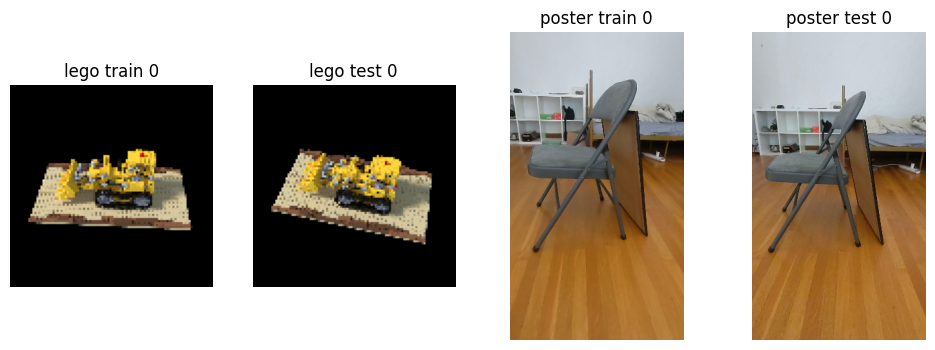

GPU memory in use: 0.98 GB


In [ ]:
# quick look at the data (lego panels only if the lego data has been loaded)
has_lego = "l_train_imgs" in globals()
panels = ([(l_train_imgs[0], "lego train 0"), (l_test_imgs[0], "lego test 0")] if has_lego else []) + \
         [(p_train_imgs[0], "poster train 0"), (p_test_imgs[0], "poster test 0")]
fig, ax = plt.subplots(1, len(panels), figsize=(3 * len(panels), 4))
for a, (im, t) in zip(ax, panels):
    a.imshow(im.cpu()); a.set_title(t); a.axis("off")
plt.show()
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

## 3. Poster: baseline and best model
The poster baseline NeRF (book MLP, 30,000 iterations), then the best model (hash grid + Mip-NeRF 360, 30,000 iterations). Both use the same 480 x 270 images and the same 29 test views. The baseline and the best model each get a 360-degree view, shown side by side at the end of the best-model cell.

In [ ]:
# Baseline NeRF: training loop and rendering (book MLP, 10x LR drop at 75 %)

@torch.no_grad()
def render_full_baseline(model, cameras, renderer):
    """Whole images. Returns rgb (B, H, W, 3) and opacity (B, H, W)."""
    out_, _ = renderer(cameras=cameras, volumetric_function=model.batched_forward)
    return out_[..., :3].clamp(0, 1), out_[..., 3]


def train_baseline(train_imgs, train_sils, train_cams, renderer_mc, renderer_grid,
                   preview_cam, preview_gt, n_iter=3000, lr=1e-3, batch_size=6, seed=1, weights_path=None, ckpt_path=None, ckpt_every=2000,
                   preview_every=2500, preview_prefix=None,
                   test_cams=None, test_imgs=None, eval_every=None):
    """Baseline NeRF training. If weights_path exists, the saved weights are loaded and no training is done."""
    torch.manual_seed(seed)
    eval_every = eval_every or preview_every
    model = NeuralRadianceField().to(device)
    if weights_path is not None and os.path.exists(weights_path):
        ck = torch.load(weights_path, map_location=device)
        model.load_state_dict(ck["model"])
        print(f"loaded saved baseline from {weights_path} (train time was {ck['stats']['train_min']:.1f} min)")
        return model, ck["stats"]
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_mse, start_it, elapsed_before, test_iter, test_psnr = [], 0, 0.0, [], []
    if ckpt_path is not None and os.path.exists(ckpt_path):                       # resume after a disconnect
        ck = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ck["model"])
        if ck["it"] + 1 > round(n_iter * 0.75):                                    # the LR drop already happened
            optimizer = torch.optim.Adam(model.parameters(), lr=lr * 0.1)
        optimizer.load_state_dict(ck["optimizer"])
        train_mse, start_it, elapsed_before = ck["train_mse"], ck["it"] + 1, ck["elapsed_min"]
        test_iter, test_psnr = ck.get("test_iter", []), ck.get("test_psnr", [])
        print(f"resumed from {ckpt_path} at iteration {start_it}")
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for it in range(start_it, n_iter):
        if it == round(n_iter * 0.75):
            print("Decreasing LR 10-fold ...")
            optimizer = torch.optim.Adam(model.parameters(), lr=lr * 0.1)
        optimizer.zero_grad()
        idx = torch.randperm(len(train_cams))[:batch_size]
        rendered, rays = renderer_mc(cameras=train_cams[idx], volumetric_function=model)
        r_img, r_sil = rendered.split([3, 1], dim=-1)
        sil_err = huber(r_sil, sample_images_at_mc_locs(train_sils[idx, ..., None], rays.xys)).abs().mean()
        gt = sample_images_at_mc_locs(train_imgs[idx], rays.xys)
        color_err = huber(r_img, gt).abs().mean()
        (color_err + sil_err).backward()
        optimizer.step()
        train_mse.append(((r_img.detach() - gt) ** 2).mean().item())
        if ckpt_path is not None and (it + 1) % ckpt_every == 0:
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "it": it,
                        "train_mse": train_mse, "test_iter": test_iter, "test_psnr": test_psnr,
                        "elapsed_min": elapsed_before + (time.time() - t0) / 60}, ckpt_path)
        if it % 250 == 0 or it == n_iter - 1:
            print(f"iter {it:5d} | color {color_err.item():.5f} | sil {sil_err.item():.5f} | {elapsed_before + (time.time() - t0) / 60:.1f} min")
        if test_cams is not None and ((it + 1) % eval_every == 0 or it == n_iter - 1):      # test PSNR during training
            rr = torch.cat([render_full_baseline(model, test_cams[[i]], renderer_grid)[0] for i in range(len(test_cams))])
            ps = (-10 * torch.log10(((rr - test_imgs) ** 2).flatten(1).mean(1))).mean().item()
            test_iter.append(it + 1); test_psnr.append(ps)
            print(f"   test PSNR at {it + 1}: {ps:.2f} | {elapsed_before + (time.time() - t0) / 60:.1f} min")
        if (it + 1) % preview_every == 0 or it == n_iter - 1:
            img, sil = render_full_baseline(model, preview_cam, renderer_grid)
            fig, ax = plt.subplots(1, 3, figsize=(8, 4))
            ax[0].imshow(img[0].cpu()); ax[0].set_title(f"render (iter {it})")
            ax[1].imshow(sil[0].cpu(), cmap="gray", vmin=0, vmax=1); ax[1].set_title("opacity")
            ax[2].imshow(preview_gt.cpu()); ax[2].set_title("ground truth")
            for a in ax: a.axis("off")
            if preview_prefix is not None:
                plt.savefig(f"{preview_prefix}_iter{it + 1:05d}.png", dpi=150, bbox_inches="tight")
            plt.show()
    stats = {"train_min": elapsed_before + (time.time() - t0) / 60, "peak_mem_gb": torch.cuda.max_memory_allocated() / 1024 ** 3,
             "train_mse": train_mse, "test_iter": test_iter, "test_psnr": test_psnr}
    print(f"done: {stats['train_min']:.1f} min, peak GPU memory {stats['peak_mem_gb']:.2f} GB")
    if weights_path is not None:
        torch.save({"model": model.state_dict(), "stats": stats}, weights_path)
    return model, stats

print("baseline defined")

baseline defined


### Baseline: poster (30,000 iterations)

iter     0 | color 0.35902 | sil 0.90499 | 0.0 min
iter   250 | color 0.07842 | sil 0.00000 | 0.4 min
iter   500 | color 0.05092 | sil 0.00000 | 0.7 min
iter   750 | color 0.04672 | sil 0.00000 | 1.0 min
iter  1000 | color 0.03868 | sil 0.00000 | 1.4 min
iter  1250 | color 0.04759 | sil 0.00000 | 1.7 min
iter  1500 | color 0.03248 | sil 0.00000 | 2.0 min
iter  1750 | color 0.03542 | sil 0.00000 | 2.4 min
iter  2000 | color 0.03883 | sil 0.00000 | 2.7 min
iter  2250 | color 0.03413 | sil 0.00000 | 3.1 min
iter  2500 | color 0.02472 | sil 0.00000 | 3.4 min
iter  2750 | color 0.03205 | sil 0.00000 | 3.7 min
iter  3000 | color 0.02923 | sil 0.00000 | 4.1 min
iter  3250 | color 0.02926 | sil 0.00000 | 4.4 min
iter  3500 | color 0.02787 | sil 0.00000 | 4.8 min
iter  3750 | color 0.02991 | sil 0.00000 | 5.1 min
iter  4000 | color 0.03172 | sil 0.00000 | 5.4 min
iter  4250 | color 0.02495 | sil 0.00000 | 5.8 min
iter  4500 | color 0.02442 | sil 0.00000 | 6.1 min
iter  4750 | color 0.02107 | si

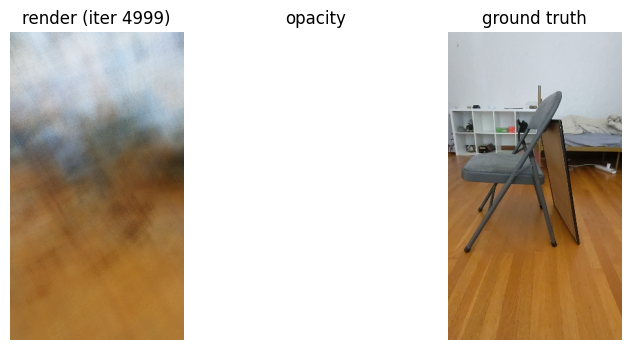

iter  5000 | color 0.03220 | sil 0.00000 | 7.2 min
iter  5250 | color 0.02673 | sil 0.00000 | 7.6 min
iter  5500 | color 0.02938 | sil 0.00000 | 7.9 min
iter  5750 | color 0.02784 | sil 0.00000 | 8.3 min
iter  6000 | color 0.02333 | sil 0.00000 | 8.6 min
iter  6250 | color 0.02362 | sil 0.00000 | 8.9 min
iter  6500 | color 0.02279 | sil 0.00000 | 9.3 min
iter  6750 | color 0.02485 | sil 0.00000 | 9.6 min
iter  7000 | color 0.02388 | sil 0.00000 | 9.9 min
iter  7250 | color 0.02405 | sil 0.00000 | 10.3 min
iter  7500 | color 0.01994 | sil 0.00000 | 10.6 min
iter  7750 | color 0.02338 | sil 0.00000 | 10.9 min
iter  8000 | color 0.02074 | sil 0.00000 | 11.3 min
iter  8250 | color 0.02302 | sil 0.00000 | 11.6 min
iter  8500 | color 0.02529 | sil 0.00000 | 12.0 min
iter  8750 | color 0.02355 | sil 0.00000 | 12.3 min
iter  9000 | color 0.02289 | sil 0.00000 | 12.6 min
iter  9250 | color 0.01859 | sil 0.00000 | 13.0 min
iter  9500 | color 0.02481 | sil 0.00000 | 13.3 min
iter  9750 | color 0.

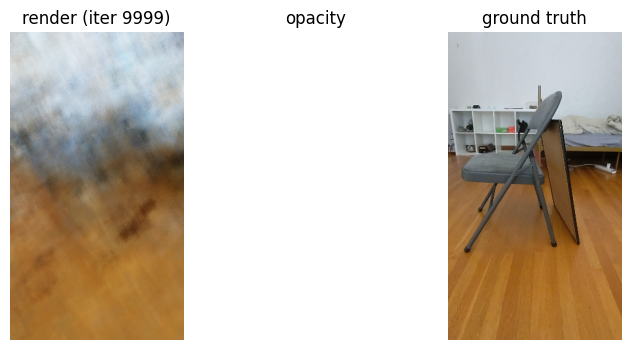

iter 10000 | color 0.02292 | sil 0.00000 | 14.4 min
iter 10250 | color 0.01973 | sil 0.00000 | 14.8 min
iter 10500 | color 0.02593 | sil 0.00000 | 15.1 min
iter 10750 | color 0.02114 | sil 0.00000 | 15.4 min
iter 11000 | color 0.02147 | sil 0.00000 | 15.8 min
iter 11250 | color 0.01853 | sil 0.00000 | 16.1 min
iter 11500 | color 0.02149 | sil 0.00000 | 16.4 min
iter 11750 | color 0.02142 | sil 0.00000 | 16.8 min
iter 12000 | color 0.02071 | sil 0.00000 | 17.1 min
iter 12250 | color 0.01721 | sil 0.00000 | 17.4 min
iter 12500 | color 0.01708 | sil 0.00000 | 17.8 min
iter 12750 | color 0.01893 | sil 0.00000 | 18.1 min
iter 13000 | color 0.02050 | sil 0.00000 | 18.5 min
iter 13250 | color 0.02242 | sil 0.00000 | 18.8 min
iter 13500 | color 0.01777 | sil 0.00000 | 19.1 min
iter 13750 | color 0.01812 | sil 0.00000 | 19.5 min
iter 14000 | color 0.02054 | sil 0.00000 | 19.8 min
iter 14250 | color 0.02056 | sil 0.00000 | 20.1 min
iter 14500 | color 0.01942 | sil 0.00000 | 20.5 min
iter 14750 |

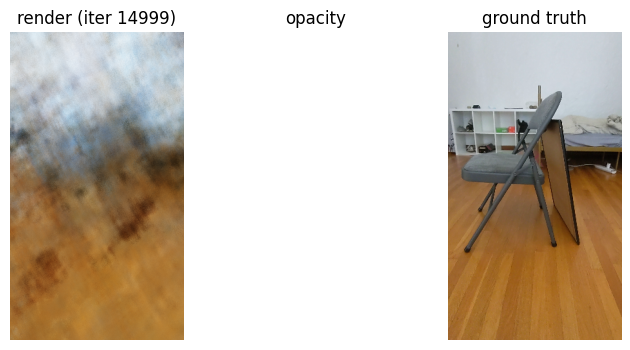

iter 15000 | color 0.01742 | sil 0.00000 | 21.6 min
iter 15250 | color 0.01854 | sil 0.00000 | 21.9 min
iter 15500 | color 0.01622 | sil 0.00000 | 22.3 min
iter 15750 | color 0.01743 | sil 0.00000 | 22.6 min
iter 16000 | color 0.01847 | sil 0.00000 | 23.0 min
iter 16250 | color 0.01823 | sil 0.00000 | 23.3 min
iter 16500 | color 0.01834 | sil 0.00000 | 23.6 min
iter 16750 | color 0.01772 | sil 0.00000 | 24.0 min
iter 17000 | color 0.01771 | sil 0.00000 | 24.3 min
iter 17250 | color 0.01667 | sil 0.00000 | 24.6 min
iter 17500 | color 0.01606 | sil 0.00000 | 25.0 min
iter 17750 | color 0.01593 | sil 0.00000 | 25.3 min
iter 18000 | color 0.01685 | sil 0.00000 | 25.7 min
iter 18250 | color 0.01771 | sil 0.00000 | 26.0 min
iter 18500 | color 0.01592 | sil 0.00000 | 26.3 min
iter 18750 | color 0.01797 | sil 0.00000 | 26.7 min
iter 19000 | color 0.01732 | sil 0.00000 | 27.0 min
iter 19250 | color 0.01548 | sil 0.00000 | 27.4 min
iter 19500 | color 0.01686 | sil 0.00000 | 27.7 min
iter 19750 |

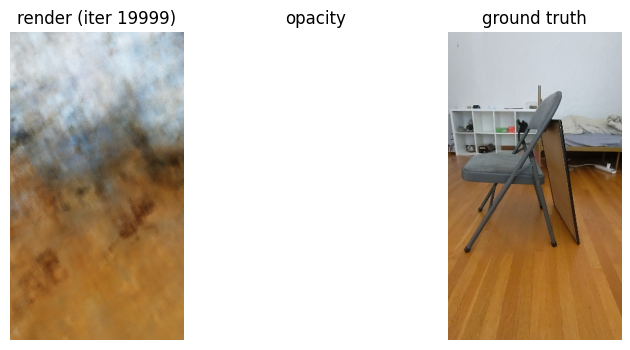

iter 20000 | color 0.01882 | sil 0.00000 | 28.8 min
iter 20250 | color 0.01702 | sil 0.00000 | 29.2 min
iter 20500 | color 0.01782 | sil 0.00000 | 29.5 min
iter 20750 | color 0.01725 | sil 0.00000 | 29.8 min
iter 21000 | color 0.01784 | sil 0.00000 | 30.2 min
iter 21250 | color 0.01835 | sil 0.00000 | 30.5 min
iter 21500 | color 0.01767 | sil 0.00000 | 30.9 min
iter 21750 | color 0.02043 | sil 0.00000 | 31.2 min
iter 22000 | color 0.01628 | sil 0.00000 | 31.5 min
iter 22250 | color 0.01887 | sil 0.00000 | 31.9 min
Decreasing LR 10-fold ...
iter 22500 | color 0.01683 | sil 0.00000 | 32.2 min
iter 22750 | color 0.01688 | sil 0.00000 | 32.6 min
iter 23000 | color 0.01415 | sil 0.00000 | 32.9 min
iter 23250 | color 0.01426 | sil 0.00000 | 33.2 min
iter 23500 | color 0.01648 | sil 0.00000 | 33.6 min
iter 23750 | color 0.01459 | sil 0.00000 | 33.9 min
iter 24000 | color 0.01365 | sil 0.00000 | 34.3 min
iter 24250 | color 0.01526 | sil 0.00000 | 34.6 min
iter 24500 | color 0.01257 | sil 0.000

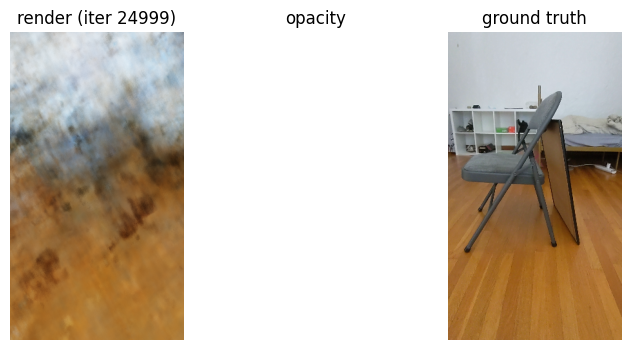

iter 25000 | color 0.01497 | sil 0.00000 | 36.1 min
iter 25250 | color 0.01539 | sil 0.00000 | 36.4 min
iter 25500 | color 0.01693 | sil 0.00000 | 36.8 min
iter 25750 | color 0.01551 | sil 0.00000 | 37.1 min
iter 26000 | color 0.01426 | sil 0.00000 | 37.4 min
iter 26250 | color 0.01557 | sil 0.00000 | 37.8 min
iter 26500 | color 0.01656 | sil 0.00000 | 38.1 min
iter 26750 | color 0.01560 | sil 0.00000 | 38.5 min
iter 27000 | color 0.01454 | sil 0.00000 | 38.8 min
iter 27250 | color 0.01590 | sil 0.00000 | 39.1 min
iter 27500 | color 0.01454 | sil 0.00000 | 39.5 min
iter 27750 | color 0.01361 | sil 0.00000 | 39.8 min
iter 28000 | color 0.01386 | sil 0.00000 | 40.2 min
iter 28250 | color 0.01477 | sil 0.00000 | 40.5 min
iter 28500 | color 0.01503 | sil 0.00000 | 40.8 min
iter 28750 | color 0.01345 | sil 0.00000 | 41.2 min
iter 29000 | color 0.01540 | sil 0.00000 | 41.5 min
iter 29250 | color 0.01357 | sil 0.00000 | 41.9 min
iter 29500 | color 0.01474 | sil 0.00000 | 42.2 min
iter 29750 |

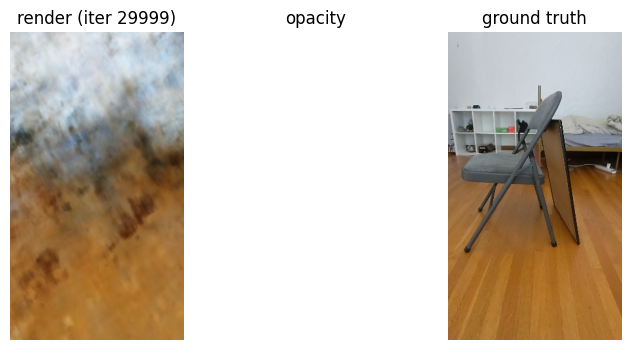

done: 43.3 min, peak GPU memory 8.08 GB


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


                                                 PSNR    SSIM   LPIPS
poster_baseline_nerf_30k                        18.72   0.609   0.666
train time: 43.3 min | peak memory: 8.08 GB


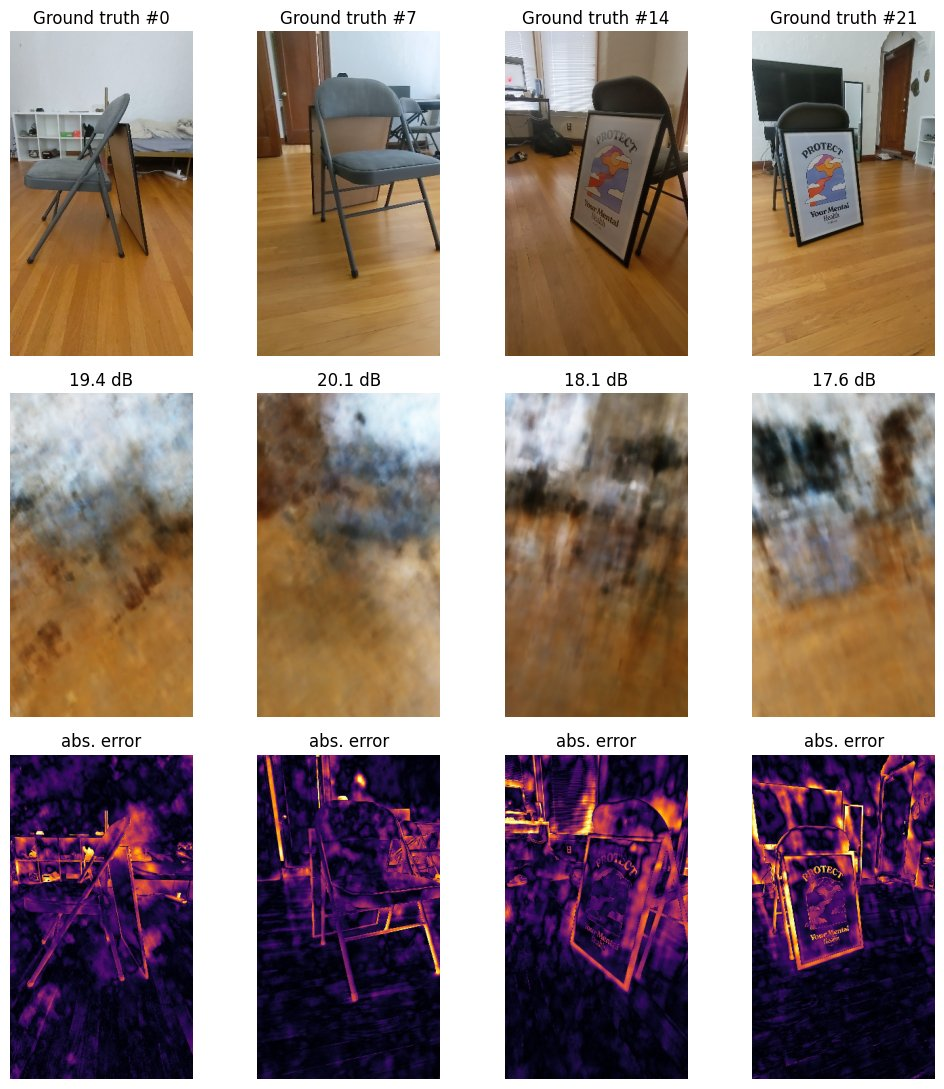

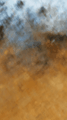

In [ ]:
# Baseline NeRF on the poster (480 x 270, 30,000 iterations), then the 29 test views
base_poster, stats_bp = train_baseline(
    p_train_imgs, p_train_sils, p_train_cams, p_renderer_mc, p_renderer_grid,
    preview_cam=p_test_cams[[0]], preview_gt=p_test_imgs[0], n_iter=30000,
    weights_path=rf("models", f"poster_baseline_nerf_30k.pt"), ckpt_path=rf("checkpoints", f"poster_baseline_nerf_30k_ckpt.pt"),
    preview_prefix=f"{rdir('training_previews', 'poster_baseline_nerf_30k')}/preview", preview_every=5000,
    test_cams=p_test_cams, test_imgs=p_test_imgs, eval_every=5000)
render_bp = lambda cams: render_full_baseline(base_poster, cams, p_renderer_grid)[0]
_ = evaluate(render_bp, p_test_cams, p_test_imgs, "poster_baseline_nerf_30k", "poster", stats_bp)
save_orbit(render_bp, "poster_baseline_nerf_30k", p_orbit_cams)      # 360-degree view of the baseline
del base_poster; torch.cuda.empty_cache()

### Best model: hash grid + Mip-NeRF 360

The best model on the poster. Ideas from Mip-NeRF 360 on top of an Instant-NGP hash grid:
- **Look-first (proposal) network**: a small density-only network finds where the surfaces are, and the main field is queried only there (online distillation, interlevel loss).
- **Scene contraction** (unbounded background squeezed into a ball) and **disparity spacing** (more samples near the camera).
- **Hash-grid field** (16 levels, 2^19 table) with two tiny MLPs instead of one big MLP.

In [ ]:
# Hash grid + Mip-NeRF 360 with the same 480 x 270 poster images, same test views, same evaluate() and 360-degree view.

import torch.nn as nn
from pytorch3d.renderer import RayBundle, ray_bundle_to_ray_points

# ---------- Mip-NeRF 360 sampling parts ----------
class Harmonic(nn.Module):
    """sin/cos of x * 0.1 * 2^k, k = 0..n-1 (same frequencies as the book's harmonic embedding)."""
    def __init__(self, n_freqs, omega0=0.1):
        super().__init__()
        self.register_buffer("freqs", omega0 * 2.0 ** torch.arange(n_freqs, dtype=torch.float32), persistent=False)
        self.dim = 2 * 3 * n_freqs
    def forward(self, x):
        e = (x[..., None] * self.freqs).flatten(-2, -1)
        return torch.cat([e.sin(), e.cos()], dim=-1)


class DensityMLP(nn.Module):
    """Look-first (proposal) network: small and density only."""
    def __init__(self, n_freqs=10, hidden=64):
        super().__init__()
        self.embed = Harmonic(n_freqs)
        self.mlp = nn.Sequential(nn.Linear(self.embed.dim, hidden), nn.Softplus(beta=10.0),
                                 nn.Linear(hidden, hidden), nn.Softplus(beta=10.0),
                                 nn.Linear(hidden, 1), nn.Softplus(beta=10.0))
        self.mlp[-2].bias.data[0] = -1.5
    def forward(self, pts):
        return self.mlp(self.embed(pts))[..., 0]


def opacity(s, deltas, delta_ref):
    return 1.0 - torch.exp(-s * deltas / delta_ref)


def weights_from_opacity(alpha):
    trans = torch.cumprod(torch.cat([torch.ones_like(alpha[..., :1]), 1.0 - alpha[..., :-1] + 1e-10], -1), -1)
    return alpha * trans


def sample_from_histogram(edges, weights, n, deterministic, padding):
    """Inverse transform sampling: n+1 sorted edges, many where the look-first weights are high."""
    w = weights + padding
    pdf = w / w.sum(-1, keepdim=True)
    cdf = torch.cat([torch.zeros_like(pdf[..., :1]), torch.cumsum(pdf, -1)], -1).clamp(max=1.0)
    m = n + 1
    if deterministic:
        u = torch.linspace(0.0, 1.0, m, device=edges.device).expand(*cdf.shape[:-1], m).contiguous()
    else:
        u = (torch.arange(m, device=edges.device) + torch.rand(*cdf.shape[:-1], m, device=edges.device)) / m
    u = u.clamp(0.0, 1.0 - 1e-6)
    i = torch.searchsorted(cdf, u, right=True)
    lo, hi = (i - 1).clamp(0, cdf.shape[-1] - 1), i.clamp(0, cdf.shape[-1] - 1)
    c_lo, c_hi = cdf.gather(-1, lo), cdf.gather(-1, hi)
    e_lo, e_hi = edges.gather(-1, lo), edges.gather(-1, hi)
    t = ((u - c_lo) / (c_hi - c_lo).clamp(min=1e-8)).clamp(0, 1)
    return torch.sort(e_lo + t * (e_hi - e_lo), -1).values


def interlevel_loss(t_nerf, w_nerf, t_prop, w_prop, eps=1e-7):
    """Mip-NeRF 360, Eq. 13 (NeRF side detached: only the look-first network learns from it)."""
    t_nerf, w_nerf = t_nerf.detach(), w_nerf.detach()
    cw = torch.cat([torch.zeros_like(w_prop[..., :1]), torch.cumsum(w_prop, -1)], -1)
    hi = torch.searchsorted(t_prop.contiguous(), t_nerf.contiguous(), right=True)
    lo, hi = (hi - 1).clamp(0, cw.shape[-1] - 1), hi.clamp(0, cw.shape[-1] - 1)
    outer = cw.gather(-1, hi)[..., 1:] - cw.gather(-1, lo)[..., :-1]
    return (F.relu(w_nerf - outer) ** 2 / (w_nerf + eps)).sum(-1).mean()


def distortion_loss_s(s, w):
    """Mip-NeRF 360, Eq. 15, in O(n) with cumulative sums."""
    u = 0.5 * (s[..., 1:] + s[..., :-1])
    uni = (w ** 2 * s.diff(dim=-1)).sum(-1) / 3.0
    wc, wuc = torch.cumsum(w, -1), torch.cumsum(w * u, -1)
    bi = 2.0 * (w[..., 1:] * u[..., 1:] * wc[..., :-1] - w[..., 1:] * wuc[..., :-1]).sum(-1)
    return (bi + uni).mean()


def scene_centre_radius(cams):
    """Centre = point closest to all viewing directions; radius = largest camera distance to it."""
    C = cams.get_camera_center().double()
    f = F.normalize(cams.R[:, :, 2].double(), dim=-1)
    eye = torch.eye(3, dtype=C.dtype, device=C.device)
    P = eye[None] - f[:, :, None] * f[:, None, :]
    lam = 1e-3 * len(C)
    centre = torch.linalg.solve(P.sum(0) + lam * eye, (P @ C[..., None])[..., 0].sum(0) + lam * C.mean(0))
    return centre.float(), float((C - centre).norm(dim=-1).max())


class OurMip360(nn.Module):
    """Look-first network (64 points) -> 128 points for the field, optional contraction + disparity sampling.
    Used as `volumetric_function` in PyTorch3D's ImplicitRenderer. The field is set by the subclass."""
    def __init__(self, near, far, n_nerf=128, contract=False, disparity=False, distortion_weight=0.0,
                 centre=(0.0, 0.0, 0.0), radius=1.0, far_inf=1000.0):
        super().__init__()
        self.near, self.far = float(near), float(far)
        self.delta_ref = (self.far - self.near) / 128
        self.n_nerf, self.dist_weight = n_nerf, distortion_weight
        self.use_contract, self.use_disparity = contract, disparity
        self.register_buffer("centre", torch.tensor(centre, dtype=torch.float32).reshape(3))
        self.radius = float(radius)
        self.t_far = far_inf if contract else self.far
        self.t_split = min(max(self.radius, 2 * self.near), 0.5 * self.t_far)
        self.proposal = DensityMLP(10, 64)
        self.prop_loss = self.dist_loss = None

    def s_to_t(self, s):
        if not self.use_disparity:
            return self.near + s * (self.t_far - self.near)
        a = (s / 0.5).clamp(max=1.0)
        b = ((s - 0.5) / 0.5).clamp(min=0.0)
        t_lin = self.near + a * (self.t_split - self.near)
        t_disp = 1.0 / ((1.0 - b) / self.t_split + b / self.t_far)
        return torch.where(s < 0.5, t_lin, t_disp)

    def even_s(self, lengths):
        K = lengths.shape[-1]
        s = torch.arange(K + 1, device=lengths.device, dtype=lengths.dtype) / K
        s = s.expand(*lengths.shape[:-1], K + 1).contiguous()
        if self.training:
            s = (s + (torch.rand(*lengths.shape[:-1], 1, device=s.device) - 0.5) / K).clamp(0.0, 1.0)
        return s

    def warp(self, pts):
        if not self.use_contract:
            return pts
        return self.radius * contract((pts - self.centre) / self.radius)    # keeps world scale inside the ball

    def field_points(self, rb, s_edges):
        t = self.s_to_t(s_edges)
        mids = 0.5 * (t[..., 1:] + t[..., :-1])
        pts = ray_bundle_to_ray_points(RayBundle(origins=rb.origins, directions=rb.directions, lengths=mids, xys=rb.xys))
        return self.warp(pts), t

    def forward(self, ray_bundle, **kwargs):
        s_p = self.even_s(ray_bundle.lengths)                              # first look
        pts, t_p = self.field_points(ray_bundle, s_p)
        w_p = weights_from_opacity(opacity(self.proposal(pts), t_p.diff(dim=-1), self.delta_ref))
        s_n = sample_from_histogram(s_p.detach(), w_p.detach(), self.n_nerf, not self.training, padding=0.01)
        pts, t_n = self.field_points(ray_bundle, s_n)                      # close look
        sig, rgb = self.nerf(pts, ray_bundle.directions)
        a = opacity(sig, t_n.diff(dim=-1), self.delta_ref)
        w = weights_from_opacity(a)
        if self.training:
            self.prop_loss = interlevel_loss(s_n, w, s_p, w_p)
            self.dist_loss = distortion_loss_s(s_n, w) if self.dist_weight > 0 else torch.zeros((), device=a.device)
        return a[..., None], rgb

    def extra_loss(self):
        return self.prop_loss + self.dist_weight * self.dist_loss

    def batched_forward(self, ray_bundle, n_batches=16, **kwargs):
        n_pts = ray_bundle.lengths.shape[-1]
        spatial = ray_bundle.origins.shape[:-1]
        outs_a, outs_c = [], []
        for idx in torch.chunk(torch.arange(spatial.numel(), device=ray_bundle.origins.device), n_batches):
            rb = RayBundle(origins=ray_bundle.origins.reshape(-1, 3)[idx], directions=ray_bundle.directions.reshape(-1, 3)[idx],
                           lengths=ray_bundle.lengths.reshape(-1, n_pts)[idx], xys=None)
            a, c = self.forward(rb)
            outs_a.append(a); outs_c.append(c)
        a, c = torch.cat(outs_a), torch.cat(outs_c)
        return a.reshape(*spatial, a.shape[-2], 1), c.reshape(*spatial, c.shape[-2], 3)


# ----------  hash grid (Instant-NGP, Mueller et al. 2022) ----------
class OurHashEncoding(nn.Module):
    """16 grids from coarse (16 cells) to fine (max_res cells); fine grids share a 2^19 table through a hash."""
    def __init__(self, n_levels=16, n_feats=2, log2_size=19, base_res=16, max_res=2048):
        super().__init__()
        self.T = 2 ** log2_size
        b = math.exp((math.log(max_res) - math.log(base_res)) / (n_levels - 1))
        self.res = [int(base_res * b ** l) for l in range(n_levels)]
        self.out_dim = n_levels * n_feats
        self.tables = nn.Parameter(torch.empty(n_levels, self.T, n_feats).uniform_(-1e-4, 1e-4))
        self.register_buffer("corners", torch.tensor([[(i >> 2) & 1, (i >> 1) & 1, i & 1] for i in range(8)]))
        self.register_buffer("primes", torch.tensor([1, 2654435761, 805459861]))

    def forward(self, x):                                   # x: (P, 3) in [0, 1)
        feats = []
        for l, R in enumerate(self.res):
            pos = x * R
            p0 = pos.floor().long()
            w = pos - p0
            c = p0[:, None, :] + self.corners
            if (R + 1) ** 3 <= self.T:
                idx = (c[..., 0] * (R + 1) + c[..., 1]) * (R + 1) + c[..., 2]
            else:
                idx = (c[..., 0] * self.primes[0]) ^ (c[..., 1] * self.primes[1]) ^ (c[..., 2] * self.primes[2])
            idx = idx % self.T
            cw = (self.corners * w[:, None, :] + (1 - self.corners) * (1 - w[:, None, :])).prod(-1)
            feats.append((F.embedding(idx, self.tables[l]) * cw[..., None]).sum(1))
        return torch.cat(feats, -1)


class OurHashField(nn.Module):
    """Hash grid + two tiny MLPs: (points, ray directions) -> (s, rgb)."""
    def __init__(self, aabb, delta_ref, max_res=2048, hidden=64, geo_feat=15, dir_freqs=4, box_only=False):
        super().__init__()
        self.register_buffer("lo", torch.tensor(aabb[0], dtype=torch.float32))
        self.register_buffer("hi", torch.tensor(aabb[1], dtype=torch.float32))
        self.enc = OurHashEncoding(max_res=max_res)
        self.delta_ref, self.dir_freqs, self.box_only = delta_ref, dir_freqs, box_only
        self.density_mlp = nn.Sequential(nn.Linear(self.enc.out_dim, hidden), nn.ReLU(inplace=True), nn.Linear(hidden, 1 + geo_feat))
        self.color_mlp = nn.Sequential(nn.Linear(geo_feat + 3 + 6 * dir_freqs, hidden), nn.ReLU(inplace=True),
                                       nn.Linear(hidden, hidden), nn.ReLU(inplace=True), nn.Linear(hidden, 3), nn.Sigmoid())

    def forward(self, pts, dirs):                           # pts (N, S, 3), dirs (N, 3)
        shape = pts.shape[:-1]
        x = ((pts.reshape(-1, 3) - self.lo) / (self.hi - self.lo)).clamp(0.0, 1.0 - 1e-6)
        h = self.density_mlp(self.enc(x))
        sigma = torch.exp(h[:, 0].clamp(max=15.0) - 1.0)
        d = F.normalize(dirs, dim=-1)[..., None, :].expand(*shape, 3).reshape(-1, 3)
        rgb = self.color_mlp(torch.cat([h[:, 1:], d, positional_encoding(d, self.dir_freqs)], -1))
        s = sigma.reshape(shape) * self.delta_ref * dirs.norm(dim=-1, keepdim=True)
        if self.box_only:                                   # lego: empty outside the box
            s = s * ((pts >= self.lo) & (pts <= self.hi)).all(-1)
        return s, rgb.reshape(*shape, 3)


class OurHashMip360(OurMip360):
    """Our final model. Poster: look-first + contraction + disparity sampling. Lego: look-first only (box)."""
    def __init__(self, near, far, aabb=None, centre=None, radius=None, max_res=2048, distortion_weight=0.0):
        if centre is not None:                              # unbounded scene (poster)
            super().__init__(near, far, contract=True, disparity=True, centre=centre, radius=radius,
                             distortion_weight=distortion_weight)
            self.nerf = OurHashField([[-2 * radius] * 3, [2 * radius] * 3], self.delta_ref, max_res=max_res)
        else:                                               # object in a box (lego)
            super().__init__(near, far, distortion_weight=distortion_weight)
            self.nerf = OurHashField(aabb, self.delta_ref, max_res=max_res, box_only=True)


@torch.no_grad()
def render_full_ours(model, cameras, renderer, n_batches=32):
    """Whole images with PyTorch3D's ImplicitRenderer: rgb (B, H, W, 3)."""
    model.eval()
    out_, _ = renderer(cameras=cameras, volumetric_function=lambda ray_bundle, **kw: model.batched_forward(ray_bundle, n_batches=n_batches))
    return out_[..., :3].clamp(0, 1)


def train_ours(train_imgs, train_cams, test_imgs, test_cams, near, far, n_iter=10000, batch_size=32, n_rays=140,
               lr_table=1e-2, lr_mlp=5e-3, lr_prop=1e-3, seed=1, eval_every=2000, ckpt_path=None, ckpt_every=2000,
               preview_every=2500, preview_prefix=None):
    """Our recipe: 32 photos x 140 rays per step, Huber loss + look-first loss, learning rates decaying to 10 %."""
    torch.manual_seed(seed)
    H_, W_ = train_imgs.shape[1:3]
    r_mc, r_grid = build_renderers(H_, W_, near, far, n_pts=64, n_rays=n_rays)
    c, rad = scene_centre_radius(train_cams)
    model = OurHashMip360(near, far, centre=c.tolist(), radius=rad).to(device)
    f = model.nerf
    optimizer = torch.optim.Adam([
        {"params": [f.enc.tables], "lr": lr_table, "eps": 1e-15},
        {"params": [*f.density_mlp.parameters(), *f.color_mlp.parameters()], "lr": lr_mlp},
        {"params": list(model.proposal.parameters()), "lr": lr_prop}], betas=(0.9, 0.99))
    gamma = 0.1 ** (1 / n_iter)
    hist = {"train_mse": [], "test_iter": [], "test_psnr": []}
    start_it, elapsed_before = 0, 0.0
    if ckpt_path is not None and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        hist, start_it, elapsed_before = ck["hist"], ck["it"] + 1, ck["elapsed_min"]
        print(f"resumed from {ckpt_path} at iteration {start_it}")
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for it in range(start_it, n_iter):
        model.train()
        optimizer.zero_grad()
        idx = torch.randperm(len(train_cams))[:batch_size]
        rendered, rays = r_mc(cameras=train_cams[idx], volumetric_function=model)
        r_img = rendered[..., :3]
        gt = sample_images_at_mc_locs(train_imgs[idx], rays.xys)
        color_err = huber(r_img, gt).abs().mean()
        (color_err + model.extra_loss()).backward()
        optimizer.step()
        for g in optimizer.param_groups: g["lr"] *= gamma
        hist["train_mse"].append(((r_img - gt) ** 2).mean().item())
        minutes = elapsed_before + (time.time() - t0) / 60
        if it % 250 == 0 or it == n_iter - 1:
            train_psnr = -10 * math.log10(np.mean(hist["train_mse"][-100:]))
            print(f"iter {it:5d} | color {color_err.item():.5f} | train PSNR {train_psnr:.2f} | {minutes:.1f} min")
        if (it + 1) % eval_every == 0 or it == n_iter - 1:
            rr = torch.cat([render_full_ours(model, test_cams[[i]], r_grid) for i in range(len(test_cams))])
            test_psnr = (-10 * torch.log10(((rr - test_imgs) ** 2).flatten(1).mean(1))).mean().item()
            hist["test_iter"].append(it + 1); hist["test_psnr"].append(test_psnr)
            print(f"   test PSNR at {it + 1}: {test_psnr:.2f} | {minutes:.1f} min")
        if (it + 1) % preview_every == 0 or it == n_iter - 1:             # picture: test view 0 vs ground truth
            img = render_full_ours(model, test_cams[[0]], r_grid)[0].cpu()
            fig, ax = plt.subplots(1, 2, figsize=(6, 5.5))
            ax[0].imshow(img); ax[0].set_title(f"render (iter {it + 1})")
            ax[1].imshow(test_imgs[0].cpu()); ax[1].set_title("ground truth")
            for a in ax: a.axis("off")
            if preview_prefix is not None:
                plt.savefig(f"{preview_prefix}_iter{it + 1:05d}.png", dpi=150, bbox_inches="tight")
            plt.show()
        if ckpt_path is not None and ((it + 1) % ckpt_every == 0 or it == n_iter - 1):
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "hist": hist,
                        "it": it, "elapsed_min": minutes}, ckpt_path)
    stats = {"train_min": elapsed_before + (time.time() - t0) / 60,
             "peak_mem_gb": torch.cuda.max_memory_allocated() / 1024 ** 3}
    print(f"done: {stats['train_min']:.1f} min, peak GPU memory {stats['peak_mem_gb']:.2f} GB")
    return model, r_grid, hist, stats

print("Hash grid + Mip-NeRF 360 defined (HashMip360, train_ours)")

Hash grid + Mip-NeRF 360 defined (HashMip360, train_ours)


### Train for 30,000 iterations, evaluate on the 29 test views, and render the 360-degree view
Resumes from the checkpoint on Drive if there is one.

iter     0 | color 0.12449 | train PSNR 12.90 | 0.0 min
iter   250 | color 0.00872 | train PSNR 24.90 | 0.4 min
iter   500 | color 0.00595 | train PSNR 27.88 | 0.8 min
iter   750 | color 0.00416 | train PSNR 28.91 | 1.2 min
iter  1000 | color 0.00471 | train PSNR 29.56 | 1.6 min
iter  1250 | color 0.00320 | train PSNR 29.98 | 2.0 min
iter  1500 | color 0.00358 | train PSNR 30.36 | 2.4 min
iter  1750 | color 0.00304 | train PSNR 30.61 | 2.7 min
iter  2000 | color 0.00334 | train PSNR 30.92 | 3.1 min
iter  2250 | color 0.00284 | train PSNR 31.08 | 3.5 min
iter  2500 | color 0.00337 | train PSNR 31.25 | 3.9 min
iter  2750 | color 0.00253 | train PSNR 31.35 | 4.3 min
iter  3000 | color 0.00265 | train PSNR 31.53 | 4.7 min
iter  3250 | color 0.00257 | train PSNR 31.61 | 5.1 min
iter  3500 | color 0.00267 | train PSNR 31.72 | 5.5 min
iter  3750 | color 0.00262 | train PSNR 31.94 | 5.9 min
iter  4000 | color 0.00261 | train PSNR 31.97 | 6.3 min
iter  4250 | color 0.00227 | train PSNR 32.23 | 

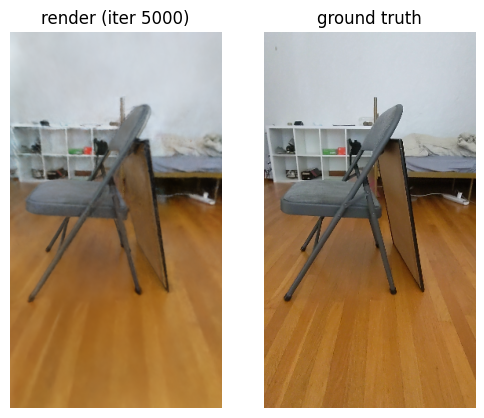

iter  5000 | color 0.00231 | train PSNR 32.46 | 8.4 min
iter  5250 | color 0.00248 | train PSNR 32.42 | 8.7 min
iter  5500 | color 0.00213 | train PSNR 32.59 | 9.1 min
iter  5750 | color 0.00204 | train PSNR 32.56 | 9.5 min
iter  6000 | color 0.00223 | train PSNR 32.63 | 9.9 min
iter  6250 | color 0.00193 | train PSNR 32.71 | 10.3 min
iter  6500 | color 0.00223 | train PSNR 32.80 | 10.7 min
iter  6750 | color 0.00223 | train PSNR 32.88 | 11.1 min
iter  7000 | color 0.00214 | train PSNR 32.79 | 11.5 min
iter  7250 | color 0.00193 | train PSNR 32.98 | 11.9 min
iter  7500 | color 0.00175 | train PSNR 33.00 | 12.3 min
iter  7750 | color 0.00185 | train PSNR 33.06 | 12.7 min
iter  8000 | color 0.00217 | train PSNR 33.22 | 13.1 min
iter  8250 | color 0.00178 | train PSNR 33.26 | 13.5 min
iter  8500 | color 0.00197 | train PSNR 33.21 | 13.9 min
iter  8750 | color 0.00185 | train PSNR 33.18 | 14.3 min
iter  9000 | color 0.00212 | train PSNR 33.33 | 14.6 min
iter  9250 | color 0.00193 | train P

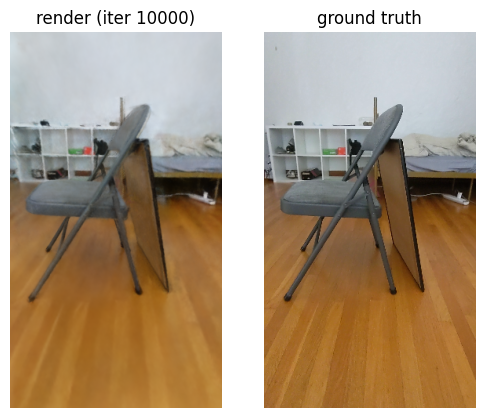

iter 10000 | color 0.00178 | train PSNR 33.43 | 16.7 min
iter 10250 | color 0.00178 | train PSNR 33.43 | 17.1 min
iter 10500 | color 0.00169 | train PSNR 33.49 | 17.5 min
iter 10750 | color 0.00180 | train PSNR 33.55 | 17.9 min
iter 11000 | color 0.00161 | train PSNR 33.60 | 18.3 min
iter 11250 | color 0.00208 | train PSNR 33.67 | 18.7 min
iter 11500 | color 0.00197 | train PSNR 33.58 | 19.1 min
iter 11750 | color 0.00184 | train PSNR 33.65 | 19.5 min
iter 12000 | color 0.00182 | train PSNR 33.51 | 19.9 min
iter 12250 | color 0.00170 | train PSNR 33.71 | 20.3 min
iter 12500 | color 0.00150 | train PSNR 33.69 | 20.7 min
iter 12750 | color 0.00167 | train PSNR 33.73 | 21.0 min
iter 13000 | color 0.00155 | train PSNR 33.74 | 21.4 min
iter 13250 | color 0.00131 | train PSNR 33.73 | 21.8 min
iter 13500 | color 0.00153 | train PSNR 33.89 | 22.2 min
iter 13750 | color 0.00186 | train PSNR 33.81 | 22.6 min
iter 14000 | color 0.00177 | train PSNR 33.84 | 23.0 min
iter 14250 | color 0.00199 | tr

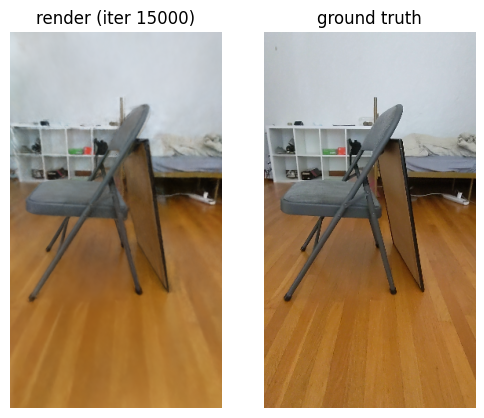

iter 15000 | color 0.00184 | train PSNR 34.05 | 25.1 min
iter 15250 | color 0.00152 | train PSNR 34.01 | 25.5 min
iter 15500 | color 0.00147 | train PSNR 34.01 | 25.9 min
iter 15750 | color 0.00127 | train PSNR 34.02 | 26.3 min
iter 16000 | color 0.00160 | train PSNR 34.09 | 26.7 min
iter 16250 | color 0.00160 | train PSNR 34.13 | 27.1 min
iter 16500 | color 0.00186 | train PSNR 34.10 | 27.5 min
iter 16750 | color 0.00146 | train PSNR 34.14 | 27.8 min
iter 17000 | color 0.00177 | train PSNR 34.23 | 28.2 min
iter 17250 | color 0.00174 | train PSNR 34.12 | 28.6 min
iter 17500 | color 0.00179 | train PSNR 34.28 | 29.0 min
iter 17750 | color 0.00134 | train PSNR 34.19 | 29.4 min
iter 18000 | color 0.00168 | train PSNR 34.26 | 29.8 min
iter 18250 | color 0.00162 | train PSNR 34.20 | 30.2 min
iter 18500 | color 0.00166 | train PSNR 34.25 | 30.6 min
iter 18750 | color 0.00174 | train PSNR 34.17 | 31.0 min
iter 19000 | color 0.00152 | train PSNR 34.38 | 31.4 min
iter 19250 | color 0.00144 | tr

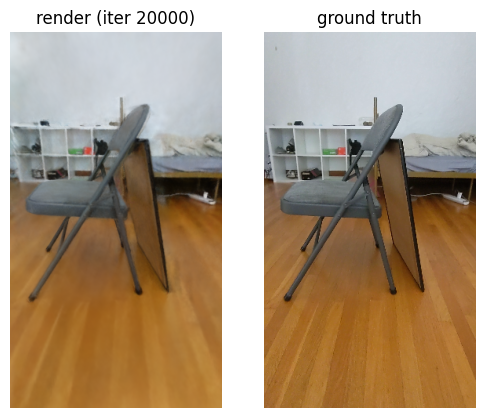

iter 20000 | color 0.00133 | train PSNR 34.39 | 33.5 min
iter 20250 | color 0.00145 | train PSNR 34.32 | 33.9 min
iter 20500 | color 0.00154 | train PSNR 34.32 | 34.3 min
iter 20750 | color 0.00163 | train PSNR 34.46 | 34.7 min
iter 21000 | color 0.00137 | train PSNR 34.45 | 35.1 min
iter 21250 | color 0.00143 | train PSNR 34.41 | 35.5 min
iter 21500 | color 0.00181 | train PSNR 34.37 | 35.8 min
iter 21750 | color 0.00140 | train PSNR 34.45 | 36.2 min
iter 22000 | color 0.00170 | train PSNR 34.37 | 36.6 min
iter 22250 | color 0.00127 | train PSNR 34.39 | 37.0 min
iter 22500 | color 0.00132 | train PSNR 34.54 | 37.4 min
iter 22750 | color 0.00124 | train PSNR 34.56 | 37.8 min
iter 23000 | color 0.00137 | train PSNR 34.42 | 38.2 min
iter 23250 | color 0.00145 | train PSNR 34.52 | 38.6 min
iter 23500 | color 0.00131 | train PSNR 34.47 | 39.0 min
iter 23750 | color 0.00140 | train PSNR 34.57 | 39.4 min
iter 24000 | color 0.00155 | train PSNR 34.44 | 39.8 min
iter 24250 | color 0.00140 | tr

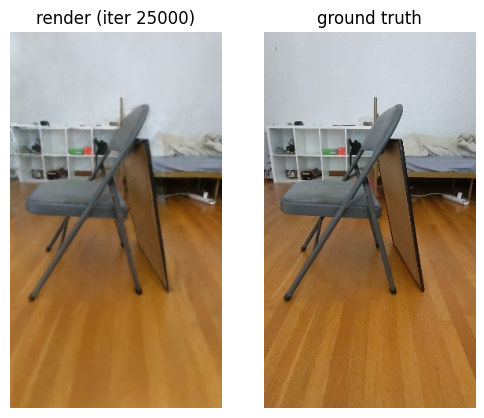

iter 25000 | color 0.00141 | train PSNR 34.63 | 41.9 min
iter 25250 | color 0.00155 | train PSNR 34.61 | 42.3 min
iter 25500 | color 0.00107 | train PSNR 34.62 | 42.6 min
iter 25750 | color 0.00150 | train PSNR 34.62 | 43.0 min
iter 26000 | color 0.00141 | train PSNR 34.56 | 43.4 min
iter 26250 | color 0.00138 | train PSNR 34.62 | 43.8 min
iter 26500 | color 0.00144 | train PSNR 34.66 | 44.2 min
iter 26750 | color 0.00148 | train PSNR 34.62 | 44.6 min
iter 27000 | color 0.00154 | train PSNR 34.58 | 45.0 min
iter 27250 | color 0.00162 | train PSNR 34.63 | 45.4 min
iter 27500 | color 0.00153 | train PSNR 34.69 | 45.8 min
iter 27750 | color 0.00144 | train PSNR 34.69 | 46.2 min
iter 28000 | color 0.00116 | train PSNR 34.68 | 46.6 min
iter 28250 | color 0.00129 | train PSNR 34.68 | 47.0 min
iter 28500 | color 0.00153 | train PSNR 34.69 | 47.4 min
iter 28750 | color 0.00138 | train PSNR 34.70 | 47.8 min
iter 29000 | color 0.00127 | train PSNR 34.70 | 48.2 min
iter 29250 | color 0.00137 | tr

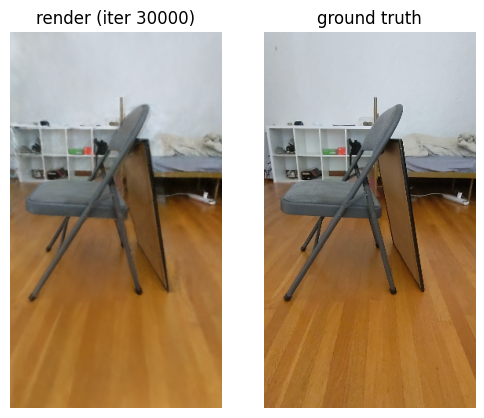

done: 50.2 min, peak GPU memory 3.31 GB
                                                 PSNR    SSIM   LPIPS
poster_ours_hash_m360_480_30k                   30.18   0.911   0.117
train time: 50.2 min | peak memory: 3.31 GB


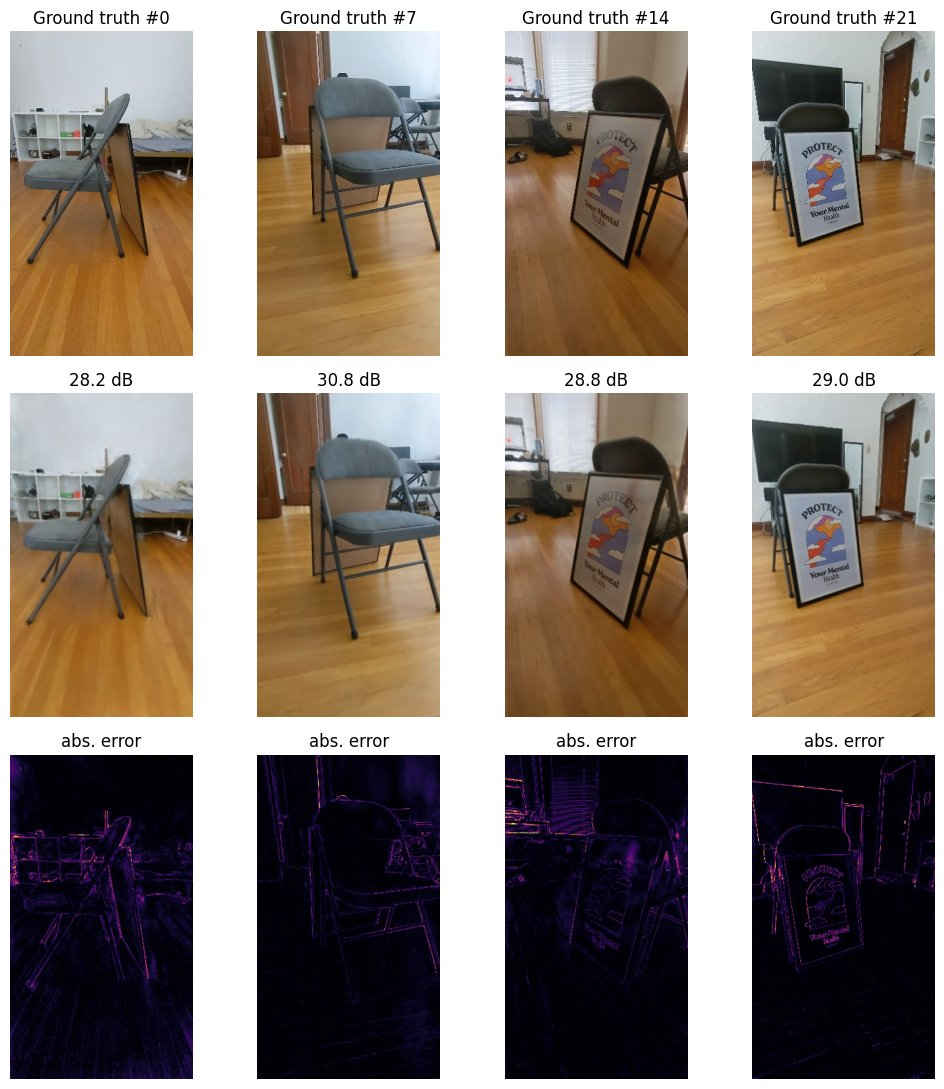

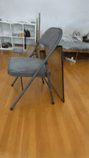

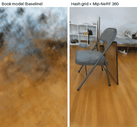

saved: /content/drive/MyDrive/ACIT4030/outputs/poster/orbit_360/poster_baseline_vs_best_orbit.gif


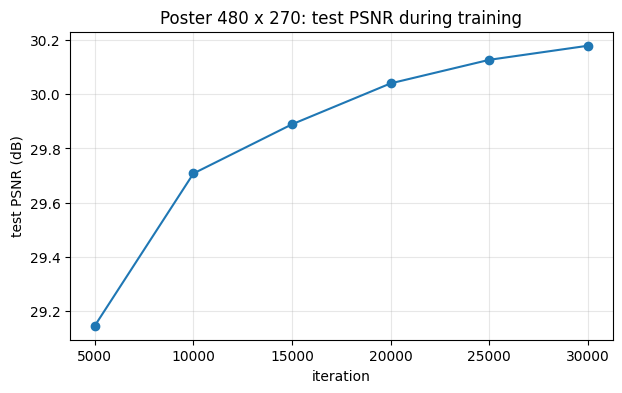

In [ ]:
# Hash grid + Mip-NeRF 360 on the poster, 480 x 270, 30,000 iterations
model_o30, r_grid_o30, hist_o30, stats_o30 = train_ours(
    p_train_imgs, p_train_cams, p_test_imgs, p_test_cams, NEAR_P, FAR_P, n_iter=30000, eval_every=5000,
    ckpt_path=rf("checkpoints", f"poster_ours_hash_m360_480_30k_ckpt.pt"),
    preview_prefix=f"{rdir('training_previews', 'poster_ours_hash_m360_480_30k')}/preview", preview_every=5000)
json.dump(hist_o30, open(rf("curves", f"poster_ours_hash_m360_480_30k_history.json"), "w"))
torch.save(model_o30.state_dict(), rf("models", f"poster_ours_hash_m360_480_30k.pt"))

render_o30 = lambda cams: render_full_ours(model_o30, cams, r_grid_o30)
renders_o30, metrics_o30 = evaluate(render_o30, p_test_cams, p_test_imgs, "poster_ours_hash_m360_480_30k", "poster", stats_o30)
save_orbit(render_o30, "poster_ours_hash_m360_480_30k", p_orbit_cams)
# 360-degree views side by side: baseline | best model
save_side_by_side("poster_baseline_nerf_30k", "Book model (baseline)",
                  "poster_ours_hash_m360_480_30k", "Hash grid + Mip-NeRF 360",
                  "poster_baseline_vs_best_orbit", scale=1)

# test PSNR during training
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_o30["test_iter"], hist_o30["test_psnr"], "o-")
ax.set_xlabel("iteration"); ax.set_ylabel("test PSNR (dB)"); ax.set_title("Poster 480 x 270: test PSNR during training")
ax.grid(alpha=0.3)
plt.savefig(rf("curves", f"poster_ours_hash_m360_480_30k_test_psnr_curve.png"), dpi=150, bbox_inches="tight"); plt.show()

## 4. Lego: baseline and D-NeRF
The Lego baseline NeRF (the same book MLP and the same training code as the poster baseline, 10,000 iterations), then D-NeRF (10,000 iterations). Both train on the same 61 photos (train + val) at 200 x 200 and are tested on the same 20 test views at 200 x 200.

### Lego baseline: the same baseline NeRF as for the poster

The Lego baseline is **exactly the poster baseline**: the book's NeRF MLP and the same `train_baseline` function from section 3, with the same loss, 128 samples per ray and the 10x learning-rate drop at 75 %. Only the data and the number of iterations differ (Lego: 10,000, poster: 30,000). It has no time input, so it must explain all photos of the moving bulldozer with one static scene; D-NeRF is given the time of every photo.

It also renders a 360-degree view, which is shown **side by side with the D-NeRF 360-degree view** at the end of section 4.

#### Lego baseline NeRF, 10,000 iterations

training cameras go all the way around -> full 360 degree circle
iter     0 | color 0.10027 | sil 0.21603 | 0.0 min
iter   250 | color 0.04398 | sil 0.05959 | 0.3 min
iter   500 | color 0.02306 | sil 0.02847 | 0.7 min
iter   750 | color 0.01597 | sil 0.01152 | 1.0 min
iter  1000 | color 0.01650 | sil 0.02028 | 1.3 min
iter  1250 | color 0.01985 | sil 0.02201 | 1.7 min
iter  1500 | color 0.01532 | sil 0.01367 | 2.0 min
iter  1750 | color 0.01378 | sil 0.01648 | 2.4 min
iter  2000 | color 0.01437 | sil 0.01632 | 2.7 min
iter  2250 | color 0.01346 | sil 0.01573 | 3.0 min
   test PSNR at 2500: 20.99 | 3.5 min


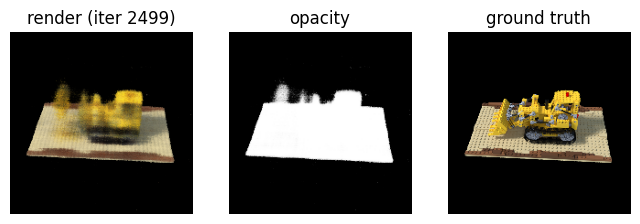

iter  2500 | color 0.01476 | sil 0.01609 | 3.5 min
iter  2750 | color 0.01373 | sil 0.01612 | 3.8 min
iter  3000 | color 0.01044 | sil 0.01760 | 4.2 min
iter  3250 | color 0.01094 | sil 0.00627 | 4.5 min
iter  3500 | color 0.01183 | sil 0.01563 | 4.8 min
iter  3750 | color 0.01086 | sil 0.01316 | 5.2 min
iter  4000 | color 0.00929 | sil 0.00655 | 5.5 min
iter  4250 | color 0.01309 | sil 0.01347 | 5.8 min
iter  4500 | color 0.00970 | sil 0.01409 | 6.2 min
iter  4750 | color 0.01099 | sil 0.01495 | 6.5 min
   test PSNR at 5000: 21.41 | 7.0 min


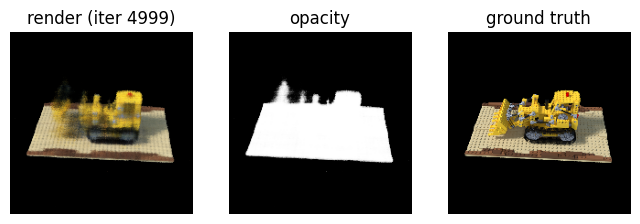

iter  5000 | color 0.01131 | sil 0.01481 | 7.0 min
iter  5250 | color 0.01031 | sil 0.00220 | 7.3 min
iter  5500 | color 0.00990 | sil 0.01838 | 7.7 min
iter  5750 | color 0.00973 | sil 0.02051 | 8.0 min
iter  6000 | color 0.01105 | sil 0.01198 | 8.3 min
iter  6250 | color 0.00779 | sil 0.00836 | 8.7 min
iter  6500 | color 0.00913 | sil 0.01167 | 9.0 min
iter  6750 | color 0.00895 | sil 0.00766 | 9.4 min
iter  7000 | color 0.00948 | sil 0.01134 | 9.7 min
iter  7250 | color 0.00896 | sil 0.01266 | 10.0 min
   test PSNR at 7500: 21.47 | 10.5 min


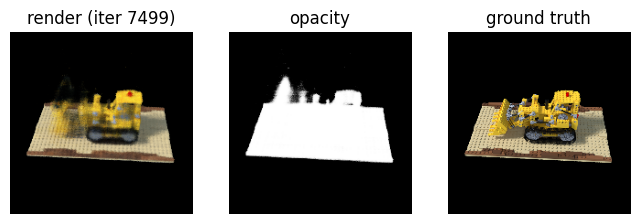

Decreasing LR 10-fold ...
iter  7500 | color 0.00794 | sil 0.00857 | 10.5 min
iter  7750 | color 0.00758 | sil 0.01078 | 10.8 min
iter  8000 | color 0.00937 | sil 0.01144 | 11.2 min
iter  8250 | color 0.00840 | sil 0.00879 | 11.5 min
iter  8500 | color 0.00868 | sil 0.00856 | 11.8 min
iter  8750 | color 0.00877 | sil 0.01519 | 12.2 min
iter  9000 | color 0.00891 | sil 0.01351 | 12.5 min
iter  9250 | color 0.00800 | sil 0.01003 | 12.9 min
iter  9500 | color 0.00810 | sil 0.01466 | 13.2 min
iter  9750 | color 0.00837 | sil 0.01060 | 13.5 min
iter  9999 | color 0.00639 | sil 0.00873 | 13.9 min
   test PSNR at 10000: 21.62 | 14.0 min


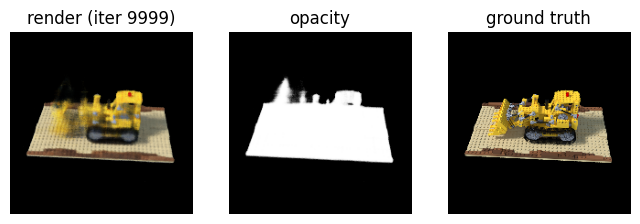

done: 14.0 min, peak GPU memory 7.49 GB
                                                 PSNR    SSIM   LPIPS
lego_baseline_nerf_200_10k                      21.62   0.862   0.147
train time: 14.0 min | peak memory: 7.49 GB


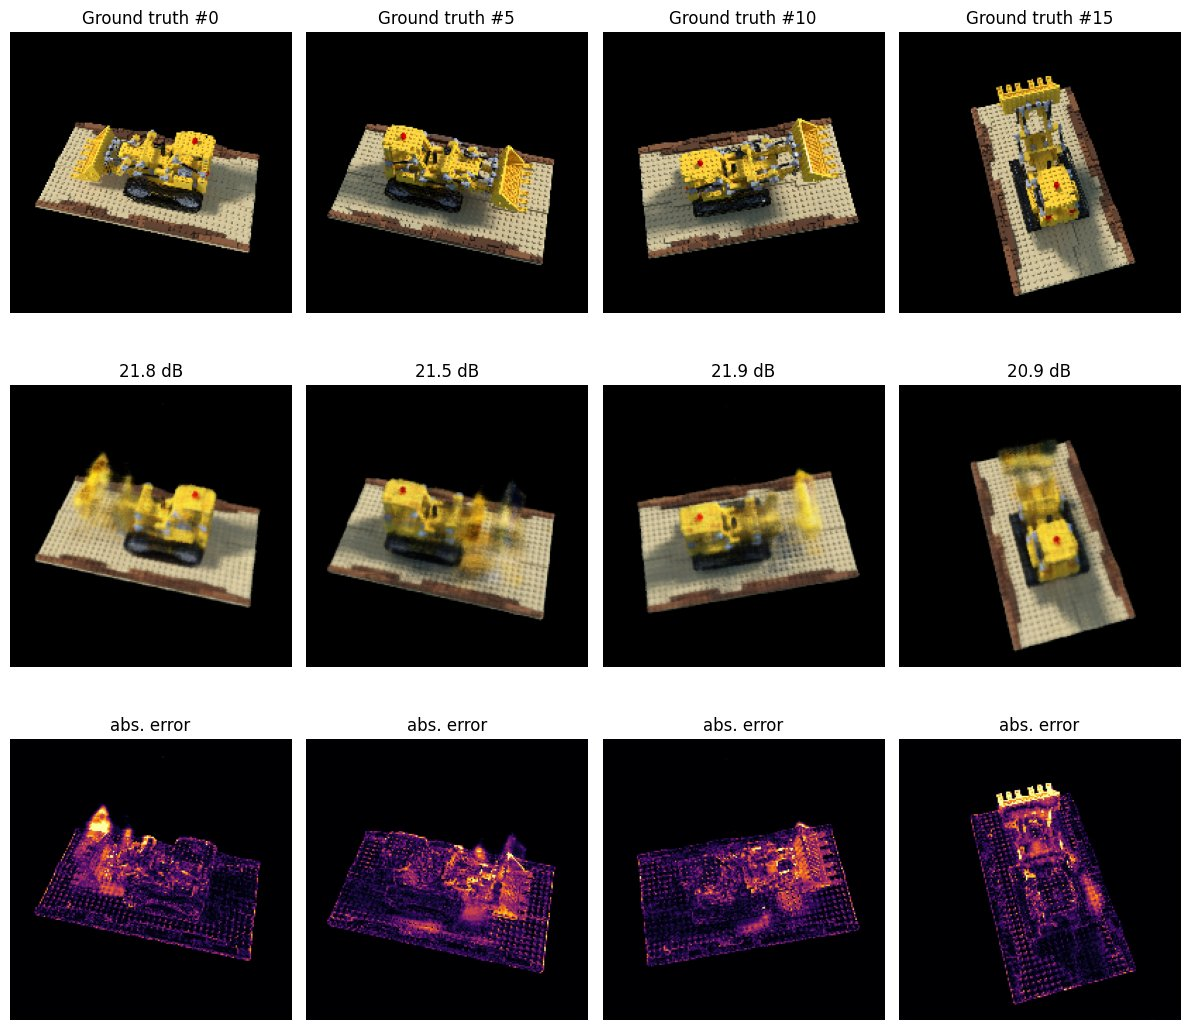

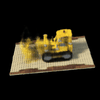

In [ ]:
# Lego baseline NeRF: the SAME book MLP and the SAME training function as the poster baseline (train_baseline),
# 10,000 iterations on the 61 Lego photos (train + val) at 200 x 200, then the 20 test views and a 360-degree view.
l_orbit_cams = orbit_cameras(l_train_cams, NEAR, FAR)          # cameras for the Lego 360-degree views
name_lb = "lego_baseline_nerf_200_10k"
base_lego, stats_lb = train_baseline(
    imgs2, sils2, cams2, r_mc2, r_grid2,
    preview_cam=cams2[[0]], preview_gt=imgs2[0], n_iter=10000,
    weights_path=rf("models", f"{name_lb}.pt"), ckpt_path=rf("checkpoints", f"{name_lb}_ckpt.pt"),
    preview_prefix=f"{rdir('training_previews', name_lb)}/preview", preview_every=2500,
    test_cams=te2[2], test_imgs=te2[0], eval_every=2500)
render_lb = lambda cams: render_full_baseline(base_lego, cams, r_grid2)[0]
_ = evaluate(render_lb, te2[2], te2[0], name_lb, "lego", stats_lb, show=(0, 5, 10, 15))
save_orbit(render_lb, name_lb, l_orbit_cams)                    # 360-degree view (no time input: the scene stays still)
del base_lego; torch.cuda.empty_cache()


### Best model: D-NeRF

The lego scene is **dynamic**: every photo shows the bulldozer at a different time `t`. D-NeRF (Pumarola et al., CVPR 2021) adds a small deformation network that moves every point `(x, t)` into one shared canonical scene, `x_c = x + dx(x, t)`. The hash grid and the colour network only see the canonical point, so the static parts are learned once and the deformation network only explains the movement.

### Hash-grid field and proposal sampling (building blocks)

In [ ]:
# Nerfacto part 1: multiresolution hash encoding (Müller et al., Instant-NGP, SIGGRAPH 2022) and the
# Nerfacto field (Tancik et al., SIGGRAPH 2023), pure PyTorch. No training happens in this cell.

class HashEncoding(torch.nn.Module):
    """
    L levels of 3D grids, from coarse (n_min cells per side) to fine (n_max cells per side).
    Each level stores feature vectors in a table of size 2^log2_T. Coarse levels that fit in the table are
    indexed directly; finer levels use the spatial hash of the paper. A point's feature at one level is the
    trilinear interpolation of the 8 surrounding corners; the features of all levels are concatenated.
    Input points must lie in [0, 1]^3.
    """
    PRIMES = (1, 2654435761, 805459861)

    def __init__(self, n_levels=16, n_features=2, log2_T=19, n_min=16, n_max=2048):
        super().__init__()
        self.n_levels, self.n_features, self.T = n_levels, n_features, 2 ** log2_T
        growth = math.exp((math.log(n_max) - math.log(n_min)) / (n_levels - 1))
        self.resolutions = [int(math.floor(n_min * growth ** l)) for l in range(n_levels)]
        self.table_sizes = [min(self.T, (r + 1) ** 3) for r in self.resolutions]
        self.tables = torch.nn.ParameterList([
            torch.nn.Parameter(torch.empty(size, n_features).uniform_(-1e-4, 1e-4)) for size in self.table_sizes])
        corners = torch.tensor([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)])
        self.register_buffer("corners", corners)                                  # (8, 3)
        self.out_dim = n_levels * n_features

    def forward(self, x):
        """x: (P, 3) in [0, 1] -> (P, n_levels * n_features)"""
        x = x.clamp(0, 1)
        feats = []
        for res, size, table in zip(self.resolutions, self.table_sizes, self.tables):
            pos = x * res
            p0 = pos.floor().long().clamp(max=res - 1)                           # lower corner of the cell
            frac = pos - p0                                                      # position inside the cell
            c = p0[:, None, :] + self.corners[None]                              # (P, 8, 3) corner coordinates
            if size < self.T:                                                    # direct indexing (no collisions)
                idx = c[..., 0] + c[..., 1] * (res + 1) + c[..., 2] * (res + 1) ** 2
            else:                                                                # spatial hash (Eq. 4 of the paper)
                idx = (c[..., 0] * self.PRIMES[0]) ^ (c[..., 1] * self.PRIMES[1]) ^ (c[..., 2] * self.PRIMES[2])
                idx = idx % self.T
            w = torch.where(self.corners[None].bool(), frac[:, None, :], 1 - frac[:, None, :]).prod(-1)   # (P, 8)
            feats.append((table[idx] * w[..., None]).sum(1))                     # (P, n_features)
        return torch.cat(feats, dim=-1)


class NerfactoField(torch.nn.Module):
    """Hash-encoded contracted position -> small density MLP; geometry features + view direction -> colour MLP."""
    def __init__(self, center, scale, geo_dim=15, hidden=64, view_freqs=4, **hash_kwargs):
        super().__init__()
        self.register_buffer("center", torch.as_tensor(center, dtype=torch.float32).reshape(3))
        self.scale = float(scale)
        self.encoding = HashEncoding(**hash_kwargs)
        self.density_mlp = torch.nn.Sequential(
            torch.nn.Linear(self.encoding.out_dim, hidden), torch.nn.ReLU(inplace=True),
            torch.nn.Linear(hidden, 1 + geo_dim))
        self.view_freqs = view_freqs
        self.color_mlp = torch.nn.Sequential(
            torch.nn.Linear(geo_dim + 3 + 2 * view_freqs * 3, hidden), torch.nn.ReLU(inplace=True),
            torch.nn.Linear(hidden, hidden), torch.nn.ReLU(inplace=True),
            torch.nn.Linear(hidden, 3), torch.nn.Sigmoid())

    def to_unit_cube(self, pts):
        """World points -> centred and scaled -> contracted into the ball of radius 2 -> mapped into [0, 1]^3."""
        return (contract((pts - self.center) / self.scale) + 2.0) / 4.0

    def forward(self, pts, dirs):
        """pts, dirs: (P, 3) -> density (P,), rgb (P, 3)"""
        h = self.density_mlp(self.encoding(self.to_unit_cube(pts)))
        sigma = torch.exp((h[:, 0] - 2.0).clamp(max=15.0))                     # truncated exp, starts small
        d = F.normalize(dirs, dim=-1)
        rgb = self.color_mlp(torch.cat([h[:, 1:], d, positional_encoding(d, self.view_freqs)], dim=-1))
        return sigma, rgb

print("HashEncoding and NerfactoField defined")

HashEncoding and NerfactoField defined


In [ ]:
# Proposal sampling (Mip-NeRF 360 / Nerfacto). A small proposal network finds where the
# surfaces are along each ray; the hash-grid field is then evaluated only at samples placed there.
#

def s_to_t(s, near, far, spacing="disparity"):
    """Normalized distance s in [0, 1] -> depth t. 'disparity': even steps in 1/t (dense near the camera)."""
    if spacing == "disparity":
        return 1.0 / (s / far + (1.0 - s) / near)
    return near + s * (far - near)


def uniform_edges(n_rays, n, train, dev):
    """n+1 sorted edges in [0, 1]: fixed ends 0 and 1, n-1 stratified-random inner edges."""
    k = torch.arange(n - 1, device=dev, dtype=torch.float32)
    jitter = torch.rand(n_rays, n - 1, device=dev) if train else 0.5
    inner = ((k + jitter) / (n - 1)).expand(n_rays, -1)
    return torch.cat([torch.zeros(n_rays, 1, device=dev), inner, torch.ones(n_rays, 1, device=dev)], dim=-1)


@torch.no_grad()
def resample_edges(edges, weights, n, train):
    """Inverse-transform sampling from the histogram (edges, weights): n+1 sorted edges, ends fixed at 0 and 1."""
    S = weights.shape[-1]
    w = weights.detach() + 0.01 / S
    pdf = w / w.sum(-1, keepdim=True)
    cdf = torch.cat([torch.zeros_like(pdf[..., :1]), pdf.cumsum(-1)], dim=-1).contiguous()
    k = torch.arange(n - 1, device=edges.device, dtype=torch.float32)
    jitter = torch.rand(edges.shape[0], n - 1, device=edges.device) if train else 0.5
    u = ((k + jitter) / (n - 1)).expand(edges.shape[0], -1).contiguous()
    idx = (torch.searchsorted(cdf, u, right=True) - 1).clamp(0, S - 1)
    cdf_lo, cdf_hi = cdf.gather(-1, idx), cdf.gather(-1, idx + 1)
    e_lo, e_hi = edges.gather(-1, idx), edges.gather(-1, idx + 1)
    frac = ((u - cdf_lo) / (cdf_hi - cdf_lo).clamp(min=1e-8)).clamp(0, 1)
    inner = (e_lo + frac * (e_hi - e_lo)).sort(dim=-1).values
    n_rays = edges.shape[0]
    return torch.cat([torch.zeros(n_rays, 1, device=edges.device), inner,
                      torch.ones(n_rays, 1, device=edges.device)], dim=-1)


def prop_loss(s_n, w_n, s_p, w_p):
    """Mip-NeRF 360 Eq. 12-13: proposal weights must upper-bound the NeRF weights (NeRF side detached)."""
    s_n, w_n = s_n.detach(), w_n.detach()
    cum = torch.cat([torch.zeros_like(w_p[..., :1]), w_p.cumsum(-1)], dim=-1)
    Sp = w_p.shape[-1]
    s_p = s_p.contiguous()
    jlo = (torch.searchsorted(s_p, s_n[..., :-1].contiguous(), right=True) - 1).clamp(0, Sp - 1)
    jhi = (torch.searchsorted(s_p, s_n[..., 1:].contiguous(), right=False) - 1).clamp(0, Sp - 1)
    jhi = torch.maximum(jhi, jlo)
    bound = cum.gather(-1, jhi + 1) - cum.gather(-1, jlo)
    return (((w_n - bound).clamp(min=0) ** 2) / (w_n + 1e-7)).sum(-1).mean()


def edge_distortion_loss(s, w):
    """Distortion loss for intervals given by edges s (N, S+1) and weights w (N, S)."""
    mid = 0.5 * (s[..., 1:] + s[..., :-1])
    width = s[..., 1:] - s[..., :-1]
    w_before = torch.cumsum(w, dim=-1) - w
    wm_before = torch.cumsum(w * mid, dim=-1) - w * mid
    pair = 2 * (w * (mid * w_before - wm_before)).sum(-1)
    return (pair + (w ** 2 * width).sum(-1) / 3.0).mean()


class ProposalNet(torch.nn.Module):
    """Small density-only network for the proposal rounds (positional encoding of the contracted point)."""
    def __init__(self, center, scale, n_freqs=8, hidden=128, n_layers=4):
        super().__init__()
        self.register_buffer("center", torch.as_tensor(center, dtype=torch.float32).reshape(3))
        self.scale, self.n_freqs = float(scale), n_freqs
        layers, d = [], 3 + 2 * n_freqs * 3
        for _ in range(n_layers - 1):
            layers += [torch.nn.Linear(d, hidden), torch.nn.ReLU(inplace=True)]; d = hidden
        self.net = torch.nn.Sequential(*layers, torch.nn.Linear(hidden, 1))
        torch.nn.init.constant_(self.net[-1].bias, -2.0)

    def forward(self, pts):
        x = contract((pts - self.center) / self.scale)
        return F.softplus(self.net(torch.cat([x, positional_encoding(x, self.n_freqs)], dim=-1)).squeeze(-1))

print("proposal sampling defined")

proposal sampling defined


### D-NeRF field (deformation network) and rendering

In [ ]:
# D-NeRF step 2: time-conditioned Nerfacto field (Pumarola et al., D-NeRF, CVPR 2021).
# A small deformation network moves every point (x, t) into one shared "canonical" scene: x_c = x + dx(x, t).
# The hash grid and the colour network only see the canonical point, so the static parts are learned once,
# and the deformation network only has to explain how the bucket moves.
# The last layer starts at zero, so training begins as the normal static Nerfacto model.

def dnerf_pipeline(field, prop, origins, dirs, times, near, far, spacing, n_prop, n_nerf, train, n_rounds=2):
    """Same proposal sampling as before; the proposal network stays static (it learns to cover every position
    the bucket visits), the final field gets the time of each ray."""
    n_rays, dev = origins.shape[0], origins.device
    dnorm = dirs.norm(dim=-1, keepdim=True)
    s = uniform_edges(n_rays, n_prop, train, dev)
    props = []
    for k in range(n_rounds):
        t = s_to_t(s, near, far, spacing)
        t_mid, delta = 0.5 * (t[..., 1:] + t[..., :-1]), t[..., 1:] - t[..., :-1]
        pts = origins[:, None, :] + dirs[:, None, :] * t_mid[..., None]
        w_p = weights_from_alpha(1.0 - torch.exp(-prop(pts) * delta * dnorm))
        props.append((s, w_p))
        s = resample_edges(s, w_p, n_prop if k < n_rounds - 1 else n_nerf, train)
    t = s_to_t(s, near, far, spacing)
    t_mid, delta = 0.5 * (t[..., 1:] + t[..., :-1]), t[..., 1:] - t[..., :-1]
    pts = origins[:, None, :] + dirs[:, None, :] * t_mid[..., None]
    n_s = t_mid.shape[-1]
    sigma, rgb, dx = field(pts.reshape(-1, 3), dirs[:, None, :].expand_as(pts).reshape(-1, 3),
                           times[:, None].expand(-1, n_s).reshape(-1))
    sigma, rgb = sigma.view(t_mid.shape), rgb.view(*t_mid.shape, 3)
    w = weights_from_alpha(1.0 - torch.exp(-sigma * delta * dnorm))
    return {"s": s, "w": w, "props": props, "color": (w[..., None] * rgb).sum(-2), "opacity": w.sum(-1),
            "deform": dx.view(*t_mid.shape, 3)}


@torch.no_grad()
def render_full_dnerf(field, prop, cameras, times, renderer, near, far, spacing, n_prop=64, n_nerf=48, chunk=4096):
    """Whole images; times: one value per camera. Returns rgb (B, H, W, 3) and opacity (B, H, W)."""
    rb = renderer.raysampler(cameras=cameras)
    shape = rb.origins.shape[:-1]
    o, d = rb.origins.reshape(-1, 3), rb.directions.reshape(-1, 3)
    tr = times.reshape(-1, *([1] * (len(shape) - 1))).expand(shape).reshape(-1).to(o.device)
    cols, ops = [], []
    for i in range(0, o.shape[0], chunk):
        r = dnerf_pipeline(field, prop, o[i:i + chunk], d[i:i + chunk], tr[i:i + chunk],
                           near, far, spacing, n_prop, n_nerf, False)
        cols.append(r["color"]); ops.append(r["opacity"])
    return torch.cat(cols).reshape(*shape, 3).clamp(0, 1), torch.cat(ops).reshape(*shape)


def make_render_fn(field, prop, renderer, near, far, spacing, ref_cams, ref_times, n_prop=64, n_nerf=48):
    """render_fn(cams) for evaluate() and save_orbit(): each camera gets the time of the matching camera
    in ref_cams (test cameras for evaluation, orbit cameras for the 360 view)."""
    def fn(cams):
        k = (ref_cams.T[None] - cams.T[:, None]).norm(dim=-1).argmin(dim=1)
        return render_full_dnerf(field, prop, cams, ref_times[k], renderer, near, far, spacing, n_prop, n_nerf)[0]
    return fn

print("D-NeRF field defined")

D-NeRF field defined


In [ ]:
# D-NeRF field: faster hash encoding + DNerfactoField (mode='deform' is the D-NeRF model used here).
# (1) Faster hash encoding: the corner weights are multiplied directly instead of with .prod(), whose
#     backward pass is very slow on the GPU when a weight is exactly 0. Only matters when the grid
#     positions need gradients, which is the case for the deformation model. Results are identical.
# (2) mode="time_input": the simpler model from the D-NeRF paper's comparison (T-NeRF): no deformation,
#     the time is given directly to the density and colour networks. As fast as the static model.

def _hash_forward_fast(self, x):
    x = x.clamp(0, 1)
    feats = []
    for res, size, table in zip(self.resolutions, self.table_sizes, self.tables):
        pos = x * res
        p0 = pos.detach().floor().long().clamp(max=res - 1)
        frac = pos - p0
        c = p0[:, None, :] + self.corners[None]
        if size < self.T:
            idx = c[..., 0] + c[..., 1] * (res + 1) + c[..., 2] * (res + 1) ** 2
        else:
            idx = (c[..., 0] * self.PRIMES[0]) ^ (c[..., 1] * self.PRIMES[1]) ^ (c[..., 2] * self.PRIMES[2])
            idx = idx % self.T
        cw = self.corners[None].to(frac.dtype)
        wa = cw * frac[:, None, :] + (1 - cw) * (1 - frac[:, None, :])          # (P, 8, 3)
        w = wa[..., 0] * wa[..., 1] * wa[..., 2]                                 # (P, 8)
        feats.append((table[idx] * w[..., None]).sum(1))
    return torch.cat(feats, dim=-1)

HashEncoding.forward = _hash_forward_fast


class DNerfactoField(NerfactoField):
    def __init__(self, center, scale, mode="deform", x_freqs=6, t_freqs=6, def_hidden=128, def_layers=4,
                 geo_dim=15, hidden=64, view_freqs=4, **hash_kwargs):
        super().__init__(center, scale, geo_dim=geo_dim, hidden=hidden, view_freqs=view_freqs, **hash_kwargs)
        self.mode, self.x_freqs, self.t_freqs = mode, x_freqs, t_freqs
        t_dim = 1 + 2 * t_freqs
        layers, d = [], 3 + 2 * x_freqs * 3 + t_dim
        for _ in range(def_layers - 1):
            layers += [torch.nn.Linear(d, def_hidden), torch.nn.ReLU(inplace=True)]; d = def_hidden
        self.deform = torch.nn.Sequential(*layers, torch.nn.Linear(def_hidden, 3))       # unused in time_input mode
        torch.nn.init.zeros_(self.deform[-1].weight); torch.nn.init.zeros_(self.deform[-1].bias)
        if mode == "time_input":                                                    # networks also see the time
            self.density_mlp = torch.nn.Sequential(
                torch.nn.Linear(self.encoding.out_dim + t_dim, hidden), torch.nn.ReLU(inplace=True),
                torch.nn.Linear(hidden, hidden), torch.nn.ReLU(inplace=True),
                torch.nn.Linear(hidden, 1 + geo_dim))

    def forward(self, pts, dirs, times):
        x = (pts - self.center) / self.scale
        t = times[:, None]
        t_enc = torch.cat([t, positional_encoding(t, self.t_freqs)], -1)
        if self.mode == "deform":
            dx = self.deform(torch.cat([x, positional_encoding(x, self.x_freqs), t_enc], -1))
            h = self.density_mlp(self.encoding((contract(x + dx) + 2.0) / 4.0))
        else:
            dx = torch.zeros_like(x)
            h = self.density_mlp(torch.cat([self.encoding((contract(x) + 2.0) / 4.0), t_enc], -1))
        sigma = torch.exp((h[:, 0] - 2.0).clamp(max=15.0))
        d = F.normalize(dirs, dim=-1)
        rgb = self.color_mlp(torch.cat([h[:, 1:], d, positional_encoding(d, self.view_freqs)], dim=-1))
        return sigma, rgb, dx

print("faster hash encoding + DNerfactoField with mode='deform' or mode='time_input'")

faster hash encoding + DNerfactoField with mode='deform' or mode='time_input'


### Training loop

In [ ]:
# D-NeRF step 3: training loop (the Nerfacto v3c loop + the time of every ray, with checkpoints)

def train_dnerfacto(train_imgs, train_times, train_cams, renderer_mc, renderer_grid, preview_cam, preview_time,
                    preview_gt, center, scale, near, far, spacing="linear", n_iter=10000, batch_size=6,
                    n_prop=64, n_nerf=48, lr_field=1e-2, lr_deform=1e-3, lr_prop=1e-3, lr_final_ratio=0.01,
                    dist_weight=0.002, deform_weight=0.0, train_sils=None, seed=1, test_cams=None, test_times=None,
                    test_imgs=None, eval_every=2000, preview_every=2500, save_prefix=None, ckpt_path=None, ckpt_every=2000,
                    **field_kwargs):
    torch.manual_seed(seed)
    field = DNerfactoField(center, scale, **field_kwargs).to(device)
    prop = ProposalNet(center, scale).to(device)
    deform_params = list(field.deform.parameters())
    other_params = [p for n, p in field.named_parameters() if not n.startswith("deform.")]
    optimizer = torch.optim.Adam([{"params": other_params, "lr": lr_field},
                                  {"params": deform_params, "lr": lr_deform},
                                  {"params": prop.parameters(), "lr": lr_prop}], eps=1e-15)
    gamma = lr_final_ratio ** (1 / n_iter)
    hist = {"train_mse": [], "test_iter": [], "test_psnr": []}
    render_test = lambda i: render_full_dnerf(field, prop, test_cams[[i]], test_times[[i]], renderer_grid,
                                              near, far, spacing, n_prop, n_nerf)[0]

    start_it, elapsed_before = 0, 0.0
    if ckpt_path is not None and os.path.exists(ckpt_path):                       # resume after an interruption
        ck = torch.load(ckpt_path, map_location=device)
        field.load_state_dict(ck["field"]); prop.load_state_dict(ck["prop"])
        optimizer.load_state_dict(ck["optimizer"])
        hist, start_it, elapsed_before = ck["hist"], ck["it"] + 1, ck["elapsed_min"]
        print(f"resumed from {ckpt_path} at iteration {start_it}")

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for it in range(start_it, n_iter):
        optimizer.zero_grad()
        idx = torch.randperm(len(train_cams))[:batch_size]
        rb = renderer_mc.raysampler(cameras=train_cams[idx])
        o, d = rb.origins.reshape(-1, 3), rb.directions.reshape(-1, 3)
        gt = sample_images_at_mc_locs(train_imgs[idx], rb.xys).reshape(-1, 3)
        ray_times = train_times[idx.to(train_times.device)][:, None].expand(-1, rb.origins.shape[1]).reshape(-1)
        r = dnerf_pipeline(field, prop, o, d, ray_times, near, far, spacing, n_prop, n_nerf, train=True)

        color_err = huber(r["color"], gt).abs().mean()
        loss = color_err + dist_weight * edge_distortion_loss(r["s"], r["w"])
        loss = loss + sum(prop_loss(r["s"], r["w"], s_k, w_k) for s_k, w_k in r["props"])
        if train_sils is not None:
            sil_gt = sample_images_at_mc_locs(train_sils[idx, ..., None], rb.xys).reshape(-1)
            loss = loss + huber(r["opacity"], sil_gt).abs().mean()
        if deform_weight > 0:                                         # optional: keep the movements small
            loss = loss + deform_weight * (r["w"].detach() * r["deform"].norm(dim=-1)).sum(-1).mean()
        loss.backward()
        optimizer.step()
        for g in optimizer.param_groups:
            g["lr"] *= gamma

        hist["train_mse"].append(((r["color"] - gt) ** 2).mean().item())
        minutes = elapsed_before + (time.time() - t0) / 60
        if it % 250 == 0 or it == n_iter - 1:
            train_psnr = -10 * math.log10(np.mean(hist["train_mse"][-100:]))
            move = (r["w"].detach() * r["deform"].detach().norm(dim=-1)).sum(-1).mean().item() * scale
            print(f"iter {it:5d} | color {color_err.item():.5f} | train PSNR {train_psnr:.2f} "
                  f"| opacity {r['opacity'].mean().item():.3f} | mean movement {move:.3f} | {minutes:.1f} min")
        if test_cams is not None and ((it + 1) % eval_every == 0 or it == n_iter - 1):
            rr = torch.cat([render_test(i) for i in range(len(test_cams))])
            test_psnr = (-10 * torch.log10(((rr - test_imgs) ** 2).flatten(1).mean(1))).mean().item()
            hist["test_iter"].append(it + 1); hist["test_psnr"].append(test_psnr)
            print(f"   test PSNR at {it + 1}: {test_psnr:.2f} | {minutes:.1f} min")
        if (it + 1) % preview_every == 0 or it == n_iter - 1:
            img, opac = render_full_dnerf(field, prop, preview_cam, preview_time, renderer_grid,
                                          near, far, spacing, n_prop, n_nerf)
            fig, ax = plt.subplots(1, 3, figsize=(9, 3))
            ax[0].imshow(img[0].cpu()); ax[0].set_title(f"render (iter {it + 1})")
            ax[1].imshow(opac[0].cpu(), cmap="gray", vmin=0, vmax=1); ax[1].set_title("opacity")
            ax[2].imshow(preview_gt.cpu()); ax[2].set_title("ground truth")
            for a in ax: a.axis("off")
            if save_prefix is not None:
                plt.savefig(f"{save_prefix}_iter{it + 1:05d}.png", dpi=150, bbox_inches="tight")
            plt.show()
        if ckpt_path is not None and ((it + 1) % ckpt_every == 0 or it == n_iter - 1):
            torch.save({"field": field.state_dict(), "prop": prop.state_dict(), "optimizer": optimizer.state_dict(),
                        "hist": hist, "it": it, "elapsed_min": minutes}, ckpt_path)

    stats = {"train_min": elapsed_before + (time.time() - t0) / 60,
             "peak_mem_gb": torch.cuda.max_memory_allocated() / 1024 ** 3}
    print(f"done: {stats['train_min']:.1f} min, peak GPU memory {stats['peak_mem_gb']:.2f} GB")
    return field, prop, hist, stats

print("train_dnerfacto defined")

train_dnerfacto defined


### Train for 10,000 iterations, evaluate on the 20 test views, and render the 360-degree views
Resumes from the checkpoint in the results folder if there is one. One GIF lets time run 0 → 1 → 0 while the camera moves around; the other freezes time at 0.5. At the end the Lego baseline and D-NeRF 360-degree views are put **side by side** in one GIF.

iter     0 | color 0.16237 | train PSNR 11.96 | opacity 0.485 | mean movement 0.000 | 0.0 min
iter   250 | color 0.01371 | train PSNR 22.11 | opacity 0.218 | mean movement 0.007 | 0.3 min
iter   500 | color 0.00854 | train PSNR 24.72 | opacity 0.234 | mean movement 0.011 | 0.7 min
iter   750 | color 0.00622 | train PSNR 25.47 | opacity 0.188 | mean movement 0.010 | 1.0 min
iter  1000 | color 0.00646 | train PSNR 26.22 | opacity 0.248 | mean movement 0.012 | 1.4 min
iter  1250 | color 0.00464 | train PSNR 26.83 | opacity 0.179 | mean movement 0.008 | 1.7 min
iter  1500 | color 0.00498 | train PSNR 27.28 | opacity 0.214 | mean movement 0.010 | 2.1 min
iter  1750 | color 0.00503 | train PSNR 27.56 | opacity 0.214 | mean movement 0.012 | 2.4 min
iter  2000 | color 0.00448 | train PSNR 27.86 | opacity 0.214 | mean movement 0.010 | 2.8 min
iter  2250 | color 0.00498 | train PSNR 28.05 | opacity 0.220 | mean movement 0.010 | 3.2 min
   test PSNR at 2500: 23.20 | 3.5 min


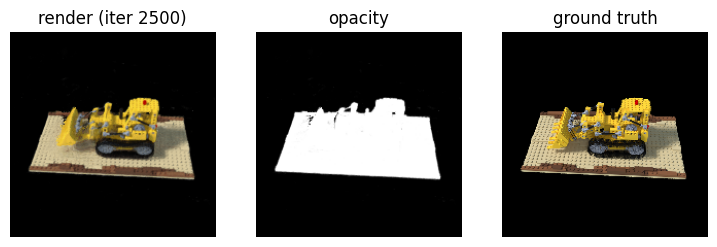

iter  2500 | color 0.00493 | train PSNR 28.26 | opacity 0.244 | mean movement 0.014 | 3.6 min
iter  2750 | color 0.00468 | train PSNR 28.55 | opacity 0.217 | mean movement 0.013 | 3.9 min
iter  3000 | color 0.00501 | train PSNR 28.56 | opacity 0.219 | mean movement 0.012 | 4.3 min
iter  3250 | color 0.00412 | train PSNR 28.90 | opacity 0.215 | mean movement 0.012 | 4.6 min
iter  3500 | color 0.00344 | train PSNR 28.96 | opacity 0.171 | mean movement 0.010 | 5.0 min
iter  3750 | color 0.00351 | train PSNR 29.08 | opacity 0.199 | mean movement 0.009 | 5.3 min
iter  4000 | color 0.00433 | train PSNR 29.18 | opacity 0.214 | mean movement 0.011 | 5.7 min
iter  4250 | color 0.00350 | train PSNR 29.34 | opacity 0.199 | mean movement 0.009 | 6.0 min
iter  4500 | color 0.00409 | train PSNR 29.22 | opacity 0.220 | mean movement 0.012 | 6.4 min
iter  4750 | color 0.00315 | train PSNR 29.45 | opacity 0.208 | mean movement 0.010 | 6.8 min
   test PSNR at 5000: 23.33 | 7.1 min


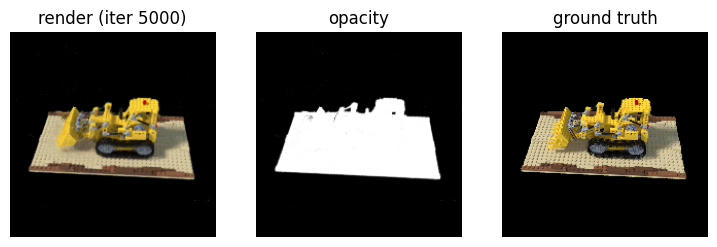

iter  5000 | color 0.00368 | train PSNR 29.50 | opacity 0.224 | mean movement 0.012 | 7.2 min
iter  5250 | color 0.00421 | train PSNR 29.80 | opacity 0.250 | mean movement 0.012 | 7.5 min
iter  5500 | color 0.00425 | train PSNR 29.59 | opacity 0.231 | mean movement 0.011 | 7.9 min
iter  5750 | color 0.00394 | train PSNR 29.62 | opacity 0.245 | mean movement 0.013 | 8.2 min
iter  6000 | color 0.00280 | train PSNR 29.60 | opacity 0.184 | mean movement 0.008 | 8.6 min
iter  6250 | color 0.00361 | train PSNR 29.73 | opacity 0.241 | mean movement 0.012 | 8.9 min
iter  6500 | color 0.00338 | train PSNR 29.71 | opacity 0.184 | mean movement 0.013 | 9.3 min
iter  6750 | color 0.00333 | train PSNR 29.59 | opacity 0.208 | mean movement 0.010 | 9.6 min
iter  7000 | color 0.00380 | train PSNR 29.76 | opacity 0.210 | mean movement 0.011 | 10.0 min
iter  7250 | color 0.00346 | train PSNR 29.75 | opacity 0.199 | mean movement 0.009 | 10.3 min
   test PSNR at 7500: 23.30 | 10.7 min


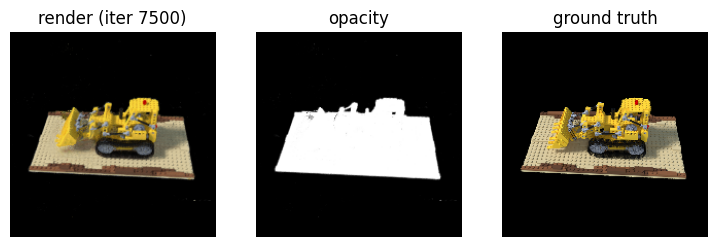

iter  7500 | color 0.00358 | train PSNR 29.79 | opacity 0.221 | mean movement 0.013 | 10.8 min
iter  7750 | color 0.00384 | train PSNR 29.80 | opacity 0.230 | mean movement 0.011 | 11.1 min
iter  8000 | color 0.00374 | train PSNR 29.80 | opacity 0.211 | mean movement 0.012 | 11.5 min
iter  8250 | color 0.00414 | train PSNR 29.82 | opacity 0.221 | mean movement 0.012 | 11.8 min
iter  8500 | color 0.00387 | train PSNR 29.74 | opacity 0.214 | mean movement 0.013 | 12.2 min
iter  8750 | color 0.00366 | train PSNR 29.84 | opacity 0.223 | mean movement 0.012 | 12.5 min
iter  9000 | color 0.00403 | train PSNR 29.91 | opacity 0.214 | mean movement 0.012 | 12.9 min
iter  9250 | color 0.00360 | train PSNR 29.92 | opacity 0.202 | mean movement 0.012 | 13.2 min
iter  9500 | color 0.00395 | train PSNR 29.81 | opacity 0.207 | mean movement 0.012 | 13.6 min
iter  9750 | color 0.00292 | train PSNR 29.83 | opacity 0.198 | mean movement 0.009 | 13.9 min
iter  9999 | color 0.00372 | train PSNR 29.83 | op

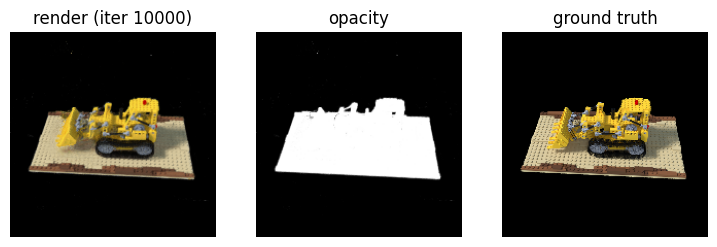

done: 14.4 min, peak GPU memory 3.89 GB
                                                 PSNR    SSIM   LPIPS
lego_dnerf_200_tv_10k                           23.30   0.867   0.108
train time: 14.4 min | peak memory: 3.89 GB


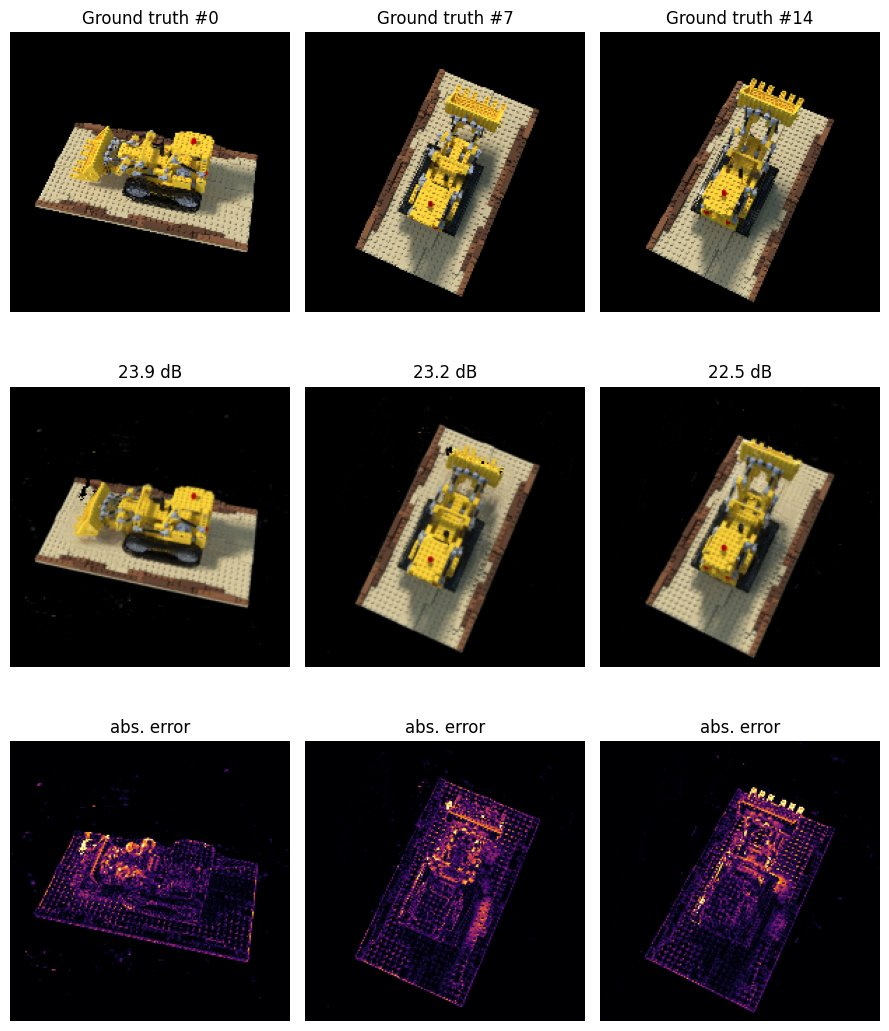

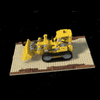

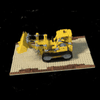

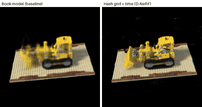

saved: /content/drive/MyDrive/ACIT4030/outputs/lego/orbit_360/lego_baseline_vs_dnerf_orbit.gif


In [ ]:
# Lego D-NeRF at 200 x 200 on train + val (61 photos), 10,000 iterations (resumes from its checkpoint if one exists).
if "l_orbit_cams" not in globals():
    l_orbit_cams = orbit_cameras(l_train_cams, NEAR, FAR)  # cameras for the Lego 360-degree views

field_d, prop_d, hist_d, stats_d = train_dnerfacto(
    imgs2, tv_times, cams2, r_mc2, r_grid2,
    preview_cam=cams2[[0]], preview_time=tv_times[[0]], preview_gt=imgs2[0],
    center=lego_center, scale=lego_scale, near=NEAR, far=FAR, spacing="linear",
    train_sils=sils2, n_iter=10000,
    test_cams=te2[2], test_times=l_test_times, test_imgs=te2[0], eval_every=2500, preview_every=2500,
    save_prefix=f"{rdir('training_previews', 'lego_dnerf_200_tv_10k')}/preview",
    ckpt_path=rf("checkpoints", f"lego_dnerf_200_tv_10k_ckpt.pt"), ckpt_every=2000)
json.dump(hist_d, open(rf("curves", f"lego_dnerf_200_tv_10k_history.json"), "w"))
torch.save({"field": field_d.state_dict(), "prop": prop_d.state_dict()}, rf("models", f"lego_dnerf_200_tv_10k.pt"))

# every test view is rendered at its own time (looking the time up by camera position gives one wrong view)
render_d = lambda cams, t: render_full_dnerf(field_d, prop_d, cams, t, r_grid2, NEAR, FAR, "linear")[0]
renders_d, metrics_d = evaluate(render_d, te2[2], te2[0], "lego_dnerf_200_tv_10k", "lego", stats_d, times=l_test_times)

n_orb = len(l_orbit_cams)
f = torch.arange(n_orb, device=device) / n_orb
moving_times = 0.5 - 0.5 * torch.cos(2 * math.pi * f)          # time goes 0 -> 1 -> 0 while the camera moves around
save_orbit(make_render_fn(field_d, prop_d, r_grid2, NEAR, FAR, "linear", l_orbit_cams, moving_times),
           "lego_dnerf_200_tv_10k_moving", l_orbit_cams)
save_orbit(make_render_fn(field_d, prop_d, r_grid2, NEAR, FAR, "linear", l_orbit_cams,
                          torch.full((n_orb,), 0.5, device=device)),
           "lego_dnerf_200_tv_10k_time05", l_orbit_cams)

# 360-degree views side by side: Lego baseline (static) | D-NeRF (the bulldozer moves while the camera goes around)
save_side_by_side("lego_baseline_nerf_200_10k", "Book model (baseline)",
                  "lego_dnerf_200_tv_10k_moving", "Hash grid + time (D-NeRF)",
                  "lego_baseline_vs_dnerf_orbit")


## 5. Training curves
Training PSNR (from the training loss, smoothed over 100 iterations) and, where it was measured, test PSNR during training. Read from the saved history/metrics files, so this cell also works after a restart. Saved in `results/curves`: one combined figure, plus one figure and CSV files per model.

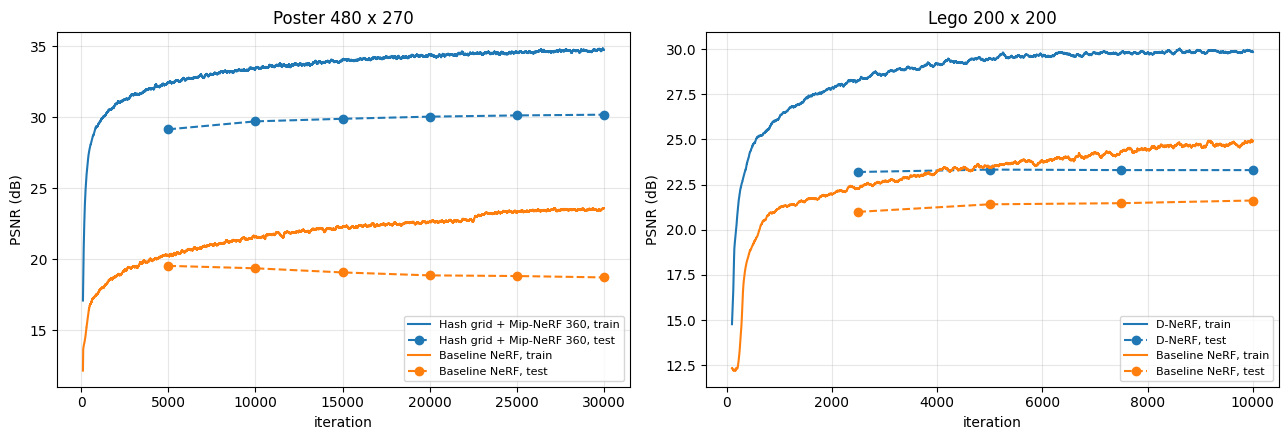

curves saved in /content/drive/MyDrive/ACIT4030/outputs/poster/curves and /content/drive/MyDrive/ACIT4030/outputs/lego/curves


In [ ]:
import pandas as pd

def train_psnr_curve(mse, k=100):
    mse = np.array(mse, dtype=np.float64)
    ps = -10 * np.log10(np.convolve(mse, np.ones(k) / k, mode="valid"))
    return np.arange(k - 1, len(mse)) + 1, ps

def load_hist(path):
    return json.load(open(path)) if os.path.exists(path) else None

h_poster = load_hist(rf("curves", f"poster_ours_hash_m360_480_30k_history.json"))
h_lego = load_hist(rf("curves", f"lego_dnerf_200_tv_10k_history.json"))
m_bp = load_hist(rf("metrics", f"poster_baseline_nerf_30k_metrics.json"))
m_bl = load_hist(rf("metrics", f"lego_baseline_nerf_200_10k_metrics.json"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, title, best, best_name, base, base_name in [
        (ax[0], "Poster 480 x 270", h_poster, "Hash grid + Mip-NeRF 360", m_bp, "Baseline NeRF"),
        (ax[1], "Lego 200 x 200", h_lego, "D-NeRF", m_bl, "Baseline NeRF")]:
    for m, name in [(best, best_name), (base, base_name)]:
        if m is not None and "train_mse" in m:
            x, y = train_psnr_curve(m["train_mse"])
            l, = a.plot(x, y, label=f"{name}, train")
            if m.get("test_iter"):
                a.plot(m["test_iter"], m["test_psnr"], "o--", color=l.get_color(), label=f"{name}, test")
    a.set_xlabel("iteration"); a.set_ylabel("PSNR (dB)"); a.set_title(title); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(rf("curves", "training_curves.png"), dpi=150, bbox_inches="tight")      # both scenes -> outputs/summary
for a, nm in zip(ax, ("poster_training_curves.png", "lego_training_curves.png")):                      # one figure per scene
    ext = a.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(rf("curves", nm), dpi=150, bbox_inches=ext.expanded(1.05, 1.1))
plt.show()

def export_curve(name, title, hist):
    """Training + test PSNR of one model: a PNG and CSV files in results/curves."""
    if hist is None or "train_mse" not in hist:
        print("no history for", name); return
    x, y = train_psnr_curve(hist["train_mse"])
    pd.DataFrame({"iteration": x, "train_psnr_smoothed_db": y}).to_csv(rf("curves", f"{name}_train_psnr.csv"), index=False)
    fig, a = plt.subplots(figsize=(7, 4))
    a.plot(x, y, label="train (smoothed over 100 iterations)")
    if hist.get("test_iter"):
        pd.DataFrame({"iteration": hist["test_iter"], "test_psnr_db": hist["test_psnr"]}).to_csv(rf("curves", f"{name}_test_psnr.csv"), index=False)
        a.plot(hist["test_iter"], hist["test_psnr"], "o--", label="test")
    a.set_xlabel("iteration"); a.set_ylabel("PSNR (dB)"); a.set_title(title); a.grid(alpha=0.3); a.legend()
    plt.tight_layout(); plt.savefig(rf("curves", f"{name}_curve.png"), dpi=150, bbox_inches="tight"); plt.close(fig)

export_curve("poster_baseline_nerf_30k", "Poster: Baseline NeRF", m_bp)
export_curve("poster_ours_hash_m360_480_30k", "Poster: Hash grid + Mip-NeRF 360", h_poster)
export_curve("lego_baseline_nerf_200_10k", "Lego: Baseline NeRF", m_bl)
export_curve("lego_dnerf_200_tv_10k", "Lego: D-NeRF", h_lego)
print("curves saved in", f"{OUT}/poster/curves and {OUT}/lego/curves")


## 6. Poster results
Evaluation on the 29 held-out poster test views (mean over views), read from the saved `*_metrics.json` files, and a comparison of four test views: ground truth against the baseline and the best model.

,model,PSNR (dB),SSIM,LPIPS,train min,peak GPU GB
0,Baseline NeRF (30k),18.72,0.609,0.666,43.3,8.08
1,Hash grid + Mip-NeRF 360 (30k),30.18,0.911,0.117,50.2,3.31


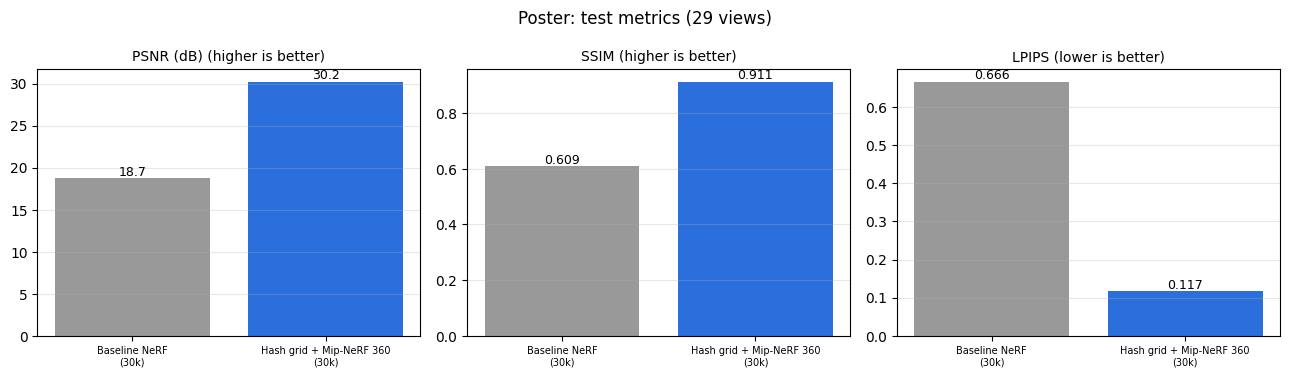

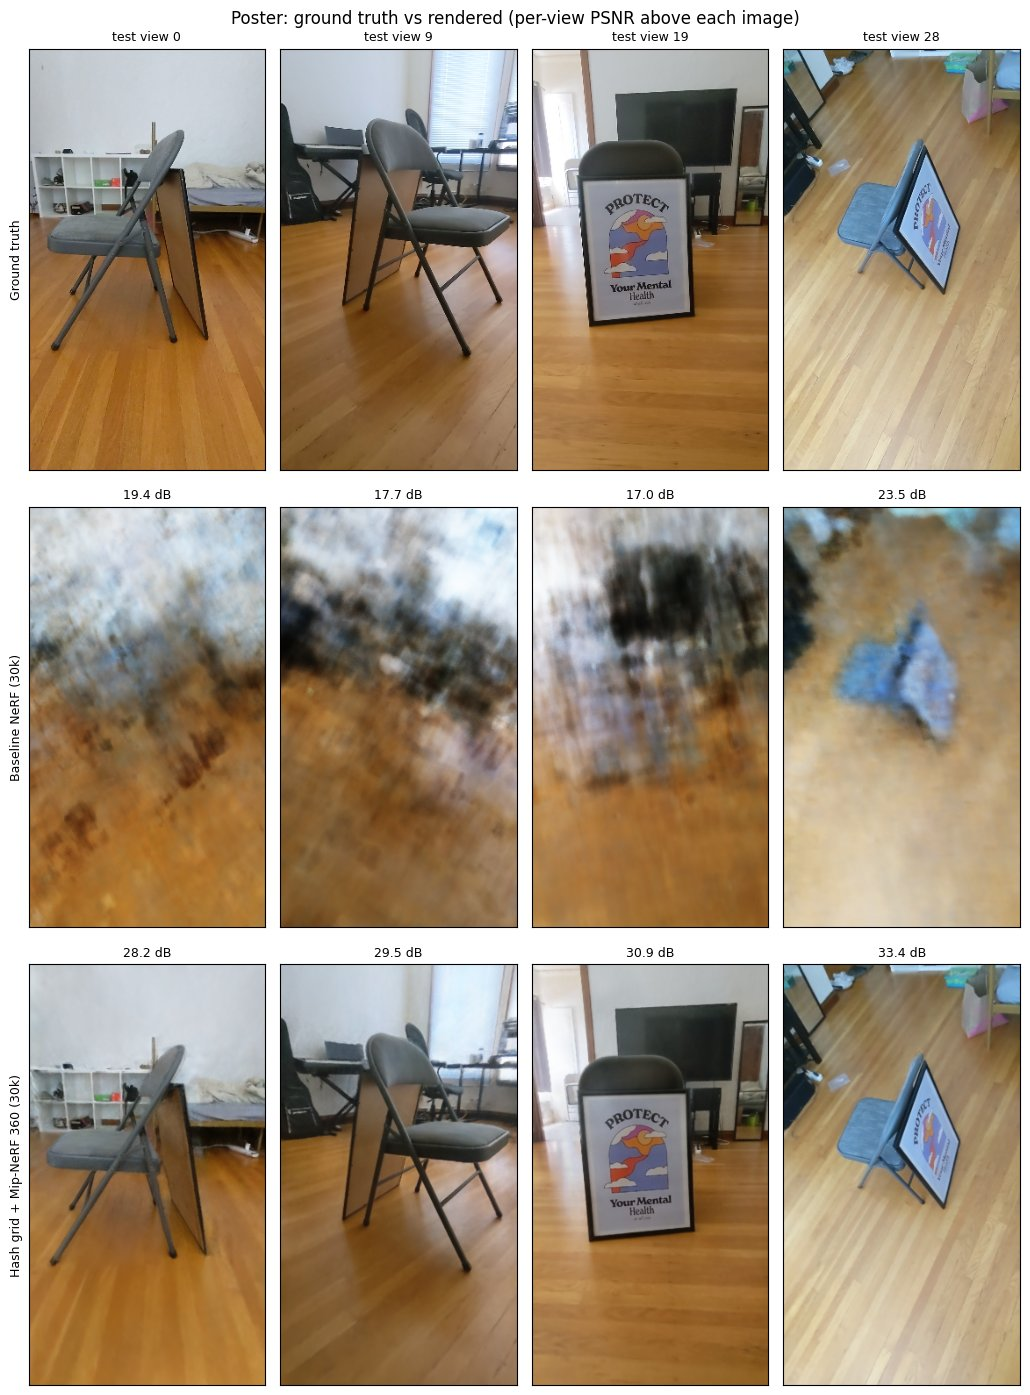

In [ ]:
import pandas as pd

def results_table(rows, csv_name):
    """rows: (label, file name). Mean PSNR / SSIM / LPIPS over the test views, plus train time and memory."""
    table = []
    for label, fname in rows:
        m = json.load(open(rf("metrics", f"{fname}_metrics.json")))
        table.append({"model": label,
                      "PSNR (dB)": round(float(np.mean(m["psnr"])), 2),
                      "SSIM": round(float(np.mean(m["ssim"])), 3),
                      "LPIPS": round(float(np.mean(m["lpips"])), 3),
                      "train min": round(m.get("train_min", float("nan")), 1),
                      "peak GPU GB": round(m.get("peak_mem_gb", float("nan")), 2)})
    df = pd.DataFrame(table)
    df.to_csv(rf("metrics", f"{csv_name}.csv"), index=False)
    return df

def metric_bars(df, title, png_name):
    """One small bar chart per metric (PSNR and SSIM: higher is better, LPIPS: lower is better)."""
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    colors = ["#999999" if m.startswith("Baseline") else "#2a6fdb" for m in df["model"]]
    for a, col, note in zip(ax, ["PSNR (dB)", "SSIM", "LPIPS"], ["higher is better", "higher is better", "lower is better"]):
        a.bar(range(len(df)), df[col], color=colors)
        for x, v in zip(range(len(df)), df[col]): a.text(x, v, f"{v:.3g}", ha="center", va="bottom", fontsize=9)
        a.set_xticks(range(len(df))); a.set_xticklabels([m.replace(" (", chr(10) + "(") for m in df["model"]], fontsize=7)
        a.set_title(f"{col} ({note})", fontsize=10); a.grid(axis="y", alpha=0.3)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(rf("comparisons", f"{png_name}.png"), dpi=150, bbox_inches="tight"); plt.show()

def compare_views(gt, models, n_views, png_name, title, tile_w=2.6):
    """Rows: ground truth, then one row per model; columns: n_views evenly spaced test views (renders read from Drive)."""
    idxs = np.linspace(0, len(gt) - 1, n_views).round().astype(int)
    rend = {name: np.load(rf("rendered_images", f"{name}/test_renders.npz"))["renders"] for _, name in models}
    mets = {name: json.load(open(rf("metrics", f"{name}_metrics.json"))) for _, name in models}
    h, w = gt.shape[1:3]
    fig, ax = plt.subplots(1 + len(models), n_views, figsize=(tile_w * n_views, tile_w * h / w * (1 + len(models)) + 0.4))
    for j, i in enumerate(idxs):
        ax[0, j].imshow(gt[i].cpu()); ax[0, j].set_title(f"test view {i}", fontsize=9)
        for r, (label, name) in enumerate(models, start=1):
            ax[r, j].imshow(rend[name][i] / 255.0)
            ax[r, j].set_title(f"{mets[name]['psnr'][i]:.1f} dB", fontsize=9)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    ax[0, 0].set_ylabel("Ground truth", fontsize=9)
    for r, (label, _) in enumerate(models, start=1): ax[r, 0].set_ylabel(label, fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(rf("comparisons", f"{png_name}.png"), dpi=150, bbox_inches="tight"); plt.show()

poster_models = [("Baseline NeRF (30k)", "poster_baseline_nerf_30k"),
                 ("Hash grid + Mip-NeRF 360 (30k)", "poster_ours_hash_m360_480_30k")]
df_poster = results_table(poster_models, "results_poster")
display(df_poster)
metric_bars(df_poster, "Poster: test metrics (29 views)", "results_poster_metrics")
compare_views(p_test_imgs, poster_models, 4, "results_poster_comparison", "Poster: ground truth vs rendered (per-view PSNR above each image)")

## 7. Lego results
Evaluation on the 20 held-out Lego test views (D-NeRF renders every view at its own time), and a comparison of four test views: ground truth against the baseline and D-NeRF.

,model,PSNR (dB),SSIM,LPIPS,train min,peak GPU GB
0,Baseline NeRF (10k),21.62,0.862,0.147,14.0,7.49
1,D-NeRF (10k),23.30,0.867,0.108,14.4,3.89


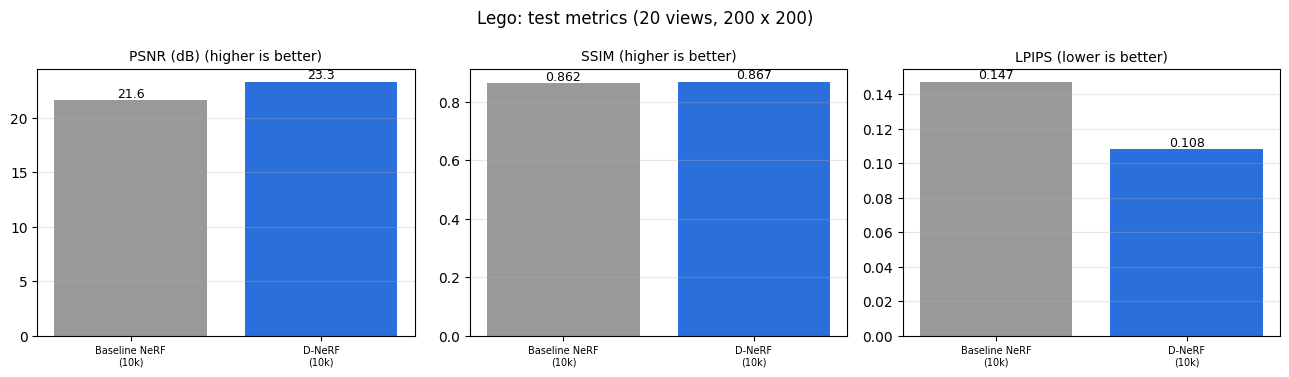

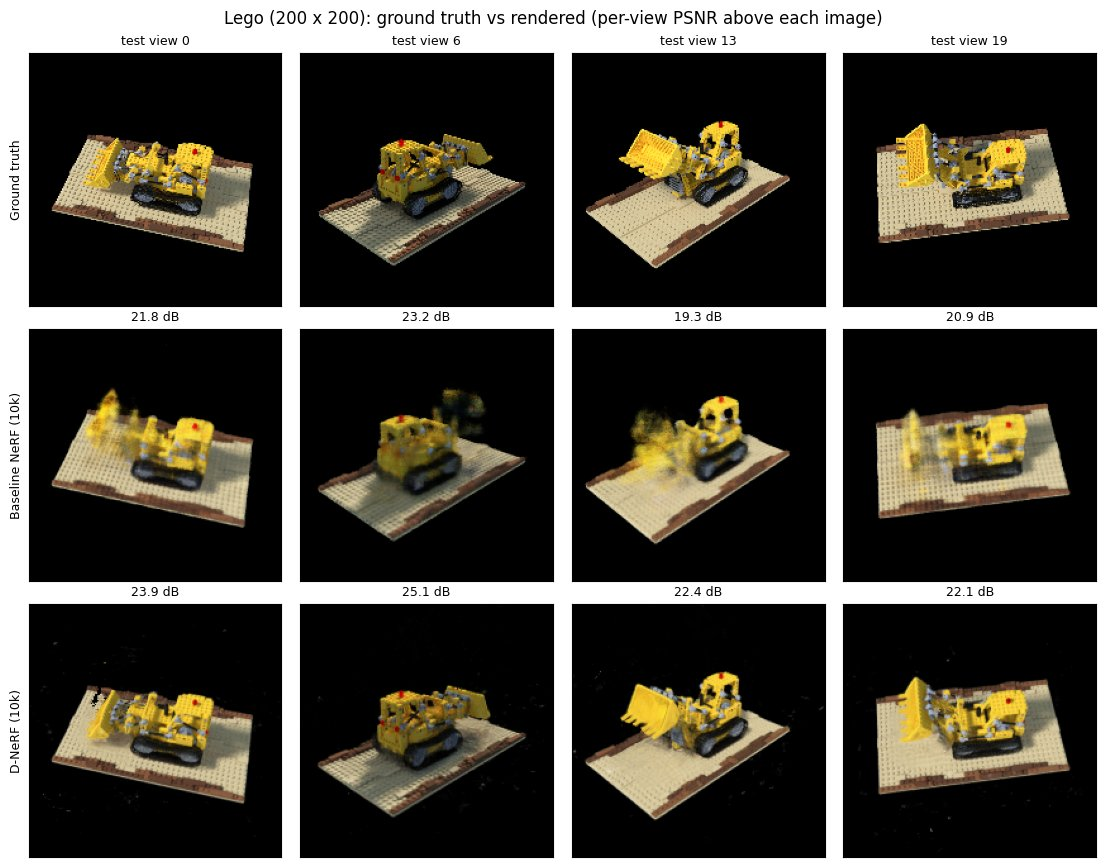

In [ ]:
lego_models = [("Baseline NeRF (10k)", "lego_baseline_nerf_200_10k"),
               ("D-NeRF (10k)", "lego_dnerf_200_tv_10k")]
df_lego = results_table(lego_models, "results_lego")
display(df_lego)
metric_bars(df_lego, "Lego: test metrics (20 views, 200 x 200)", "results_lego_metrics")
compare_views(te2[0], lego_models, 4, "results_lego_comparison", "Lego (200 x 200): ground truth vs rendered (per-view PSNR above each image)", tile_w=2.8)


In [ ]:
# Evaluation summary of all four models (Poster and Lego) in one table, read from the saved *_metrics.json files
import pandas as pd

models = [("Poster", "Baseline NeRF (30k)",                "poster_baseline_nerf_30k"),
          ("Poster", "Hash grid + Mip-NeRF 360 (30k)",     "poster_ours_hash_m360_480_30k"),
          ("Lego",   "Baseline NeRF (10k)",                "lego_baseline_nerf_200_10k"),
          ("Lego",   "D-NeRF (10k)",                       "lego_dnerf_200_tv_10k")]

rows = []
for scene, label, fname in models:
    path = rf("metrics", f"{fname}_metrics.json")
    if not os.path.exists(path):
        print("missing (not trained / evaluated yet):", fname); continue
    m = json.load(open(path))
    rows.append({"scene": scene, "model": label,
                 "views": len(m["psnr"]),
                 "PSNR (dB)": round(float(np.mean(m["psnr"])), 2),
                 "SSIM": round(float(np.mean(m["ssim"])), 3),
                 "LPIPS": round(float(np.mean(m["lpips"])), 3),
                 "train min": round(m.get("train_min", float("nan")), 1),
                 "peak GPU GB": round(m.get("peak_mem_gb", float("nan")), 2)})

df_all = pd.DataFrame(rows)
df_all.to_csv(rf("metrics", f"results_all_models.csv"), index=False)
display(df_all.style.hide(axis="index").format({"PSNR (dB)": "{:.2f}", "SSIM": "{:.3f}", "LPIPS": "{:.3f}"}))
print("GPU of this session:", torch.cuda.get_device_name(0), "| saved:", rf("metrics", f"results_all_models.csv"))

scene,model,views,PSNR (dB),SSIM,LPIPS,train min,peak GPU GB
Poster,Baseline NeRF (30k),29,18.72,0.609,0.666,43.300000,8.080000
Poster,Hash grid + Mip-NeRF 360 (30k),29,30.18,0.911,0.117,50.200000,3.310000
Lego,Baseline NeRF (10k),20,21.62,0.862,0.147,14.000000,7.490000
Lego,D-NeRF (10k),20,23.30,0.867,0.108,14.400000,3.890000


GPU of this session: NVIDIA A100-SXM4-40GB | saved: /content/drive/MyDrive/ACIT4030/outputs/summary/results_all_models.csv


## 8. Results folder
Number of files in each sub-folder of `outputs/poster` and `outputs/lego`.

In [ ]:
for sc in SCENES:
    print(sc)
    for k in KINDS:
        n = sum(len(fs) for _, _, fs in os.walk(f"{OUT}/{sc}/{k}"))
        print(f"   {sc}/{k:20s} {n:4d} files")
print("summary:", sorted(os.listdir(f"{OUT}/summary")))
print("\n360-degree comparisons:", f"{OUT}/poster/orbit_360/poster_baseline_vs_best_orbit.gif", "|", f"{OUT}/lego/orbit_360/lego_baseline_vs_dnerf_orbit.gif")


poster
   poster/models                  2 files
   poster/checkpoints             2 files
   poster/metrics                 5 files
   poster/curves                  9 files
   poster/rendered_images       120 files
   poster/training_previews      12 files
   poster/comparisons             2 files
   poster/orbit_360               6 files
lego
   lego/models                  2 files
   lego/checkpoints             2 files
   lego/metrics                 5 files
   lego/curves                  8 files
   lego/rendered_images        84 files
   lego/training_previews       8 files
   lego/comparisons             2 files
   lego/orbit_360               8 files
summary: ['results_all_models.csv', 'training_curves.png']

360-degree comparisons: /content/drive/MyDrive/ACIT4030/outputs/poster/orbit_360/poster_baseline_vs_best_orbit.gif | /content/drive/MyDrive/ACIT4030/outputs/lego/orbit_360/lego_baseline_vs_dnerf_orbit.gif
